1. The Consolidated Requirements
  * Chip Architecture & Physical Properties
    * Dual-Plane Routing (Flip-Chip): The router navigates across a bottom planar device and a top chip.
    * Dynamic CPW Parameters: The top and bottom chips use different CPW dimensions (center conductor width and gap width).
    * Trapezoidal Transition Pieces: Automatically inserted at the exact boundary crossing to connect differing CPW dimensions smoothly and avoid microwave impedance mismatches.
  * User Controls & Path Guides
    * Port Extensions: The start and end of the CPW must extend straight out from their ports for a predefined distance before A* takes over.
    * Anchors (Waypoints): User-defined coordinate points that the CPW must pass through to guide the general flow of the route.
  * Clearance & Collision Constraints (The 3 Boundary Types)
    * Forbidden Regions: Absolute "no-go" corners of the top chip (defined by $l_x$ and $l_y$). Nodes cannot be created here under any circumstances.
    * Boundary Crossing Zone ($\pm d$): A rectangular margin (width $2d$) along the top chip edge to account for bonding/die-shift errors. Traces must cross this zone perfectly perpendicularly.
    * Object Boundaries with Exact Buffers (Two-Tier Clearance):
      * Broad-Phase Box: A rectangular bounding box around every component, artificially expanded by a "buffer" distance.
      * Narrow-Phase Clearance: If a path enters the Broad-Phase box, it must maintain a strict minimum distance (the buffer) from the true object geometry and absolutely cannot intersect it.
2. The Final Algorithm Steps
  * Step 1: Pre-Processing (The Setup Phase)
    * Define the geometric coordinates for the Forbidden Regions (the corners).
    * Define the Boundary Crossing Zone (the $\pm d$ rectangle around the top chip edge).
    * Iterate through all objects on the chip, grab their standard rectangular bounding boxes, and expand them by the buffer distance to create the Expanded Bounding Boxes (Broad-Phase).
    * Build the sequential waypoint list: Start Port Extension $\rightarrow$ Anchor 1 $\rightarrow$ Anchor N $\rightarrow$ End Port Extension.
  * Step 2: Segmented Waypoint Navigation
    * Run the A* pathfinder segment by segment (e.g., from the Start Extension to Anchor 1) to keep the search space small and efficient.
  * Step 3: Node Generation & The "Jump" Mechanic: From the current node, look at the adjacent grid points (Up, Down, Left, Right).
    * Normal Grid Step: Create a standard line segment to the adjacent point.
    * The "Jump": If the adjacent point lands inside the Boundary Crossing Zone ($\pm d$), snap to the entry edge, project a straight line across to the exit edge, and place the target node there. This forces a perpendicular bridge across the bonding margin and flags the center for a Trapezoidal Transition Piece.
  * Step 4: The Optimized Validation Order (Short-Circuit Evaluation)Test every proposed line segment (normal step or "jump" bridge) in this specific order to save CPU cycles:
    * Check 1: Forbidden Regions (Fastest): Does the target node land inside a forbidden corner?
      * If Yes: Discard the path immediately.
      * If No: Proceed to Check 2.
    * Check 2: Object Collisions & Clearance (The Buffer Test): * Broad-Phase: Does the line segment enter any object's Expanded Bounding Box?
      * If No: The path is clear. Proceed to step 5.
      * If Yes: Perform the Narrow-Phase check. Calculate the exact shortest distance from the line segment to the true object geometry.
      * Narrow-Phase: Is the calculated distance $\le$ buffer, OR does the segment physically intersect the object geometry?
        * If Yes: The path is too close or hitting the object. Discard the path.
        * If No: The path is valid. Proceed to step 5.
  * Step 5: Cost Calculation & IterationIf the node passes both checks, calculate its A* cost (actual distance traveled + Manhattan distance to the current waypoint). Add it to the open list and repeat Steps 3 and 4 until the target waypoint is reached.
  * Step 6: Post-ProcessingOnce all segments are connected, apply corner filleting (rounding 90-degree turns while respecting minimum segment lengths to prevent short circuits). Finally, render the generated CPW geometry and the transition trapezoids onto the Qiskit Metal canvas.

# Advanced Flip-Chip Routing Algorithm: Strategy & Concept Guide (V2)

## 1. Core Architecture & Routing Strategies
* **Dual-Plane Routing & Automated Transitions:** Navigates across a base "planar" device and a suspended "flip-chip." When the trace crosses the mathematical boundary of the top chip, the algorithm automatically drops an anchor, swaps Qiskit Metal drawing layers, and generates a smooth, trapezoidal CPW transition polygon to prevent microwave impedance mismatches between the different CPW widths/gaps.
* **Stateful Continuous A\* Search:** Instead of routing greedy, disconnected segments between anchors, the algorithm uses a "Stateful" A* engine. A single, continuous search explores the grid. The state is tracked as `(x, y, target_idx)`. When the algorithm hits an anchor, it simply upgrades its state to the next target and continues routing, ensuring global awareness of the entire path.
* **Orthogonal vs. Continuous (Diagonal) Modes:** * *Orthogonal Mode:* Restricts the A* grid to strict 90-degree stair-case turns, mimicking traditional digital routing.
  * *Continuous Mode:* Allows diagonal expansion in the A* grid. In post-processing, a line-of-sight smoothing algorithm sweeps the trace, pruning intermediate nodes and replacing them with smooth diagonal cuts between obstacles.

## 2. Dynamic Constraints & Mathematical Safety Methods
* **Dynamic Grid Auto-Scaling:** The A* `step_size` is no longer static. If the user requests a grid step that is mathematically too small to clear the required `obstacle_buffer` or execute the required `fillet` radius, the algorithm silently scales the grid up. This prevents the router from stepping "inside" a wall or generating physically impossible short segments.
* **Epsilon Deflation:** A standard computational geometry technique. All physical obstacle buffers are dynamically deflated by a microscopic epsilon (`1 nm` or `1e-3 um`). This prevents Shapely floating-point math from falsely flagging traces that safely hug the exact mathematical border of a keep-out zone, completely eliminating "TRAPPED" errors.
* **Dynamic Fillet Pruning & Safety Overrides:** RF traces cannot make sharp turns; they require massive corner fillets. The algorithm evaluates the user's `port_extension`. If it is shorter than the physical space needed to turn the corner (`2.05 * fillet`), the router dynamically overrides it to the safe minimum to prevent Qiskit Metal from crashing.
* **End-Pin & Intermediate Vertex Pruning:** Before rendering, the algorithm sweeps the final path. Any segment that is shorter than the minimum safe fillet distance is pruned out, ensuring the Qiskit Metal geometry fillet engine never mathematically fails.

## 3. Collision Engine & Keep-Out Zones
* **The Two-Tier Physical Collision Check:** Every movement candidate is tested against a dynamic collision table:
  1. *Broad-Phase (Box Check):* Fast check against an inflated rectangular bounding box around every component. If clear, proceed.
  2. *Narrow-Phase (Geometry Check):* If the box is entered, perform a highly accurate Shapely intersection check against the true, epsilon-deflated buffer geometry.
* **Virtual Escape Zones (Directional Tunnels):** To prevent the router from crowding un-used component ports, the algorithm dynamically generates massive "invisible tunnels" projecting forward from every open pin. Controlled by a single `port_keepout` parameter, these rectangular zones act as reserved highways, guaranteeing future traces will have physical space to escape their ports and turn.
* **Snake Footprint (Self-Collision Avoidance):** When drawing complex delay lines, U-turns, or meanders, the router must not short-circuit its own trace. The algorithm maintains a memory of its historical footprint. When validating diagonal jumps, it calculates its distance from its own tail to ensure a strict minimum internal gap is maintained.

## 4. The Optimized Algorithm Execution Order
* **Step 1: Environment & Memory Setup**
  Parse all geometries, build the deflated physical buffer tables, generate the Virtual Escape tunnels, and calculate all mathematical minimums (grid scaling, safe extensions).
* **Step 2: Boundary Safety & Anchor Splitting**
  Scan all user anchors. If any anchor sits dangerously on the exact edge of the flip-chip (which would cause a manufacturing clipping error), split the anchor into two safe waypoints on either side of the gap, forcing a perpendicular jump.
* **Step 3: Stateful A* Expansion**
  Pop the lowest-cost node from the priority queue. Generate up to 8 neighbors (if continuous) or 4 neighbors (if orthogonal).
* **Step 4: The Short-Circuit Validation Order**
  Test every proposed step in this exact order to save CPU cycles:
  * *Check 1: Fast Boundaries.* Is the node outside the absolute chip boundaries? -> Discard.
  * *Check 2: Flip-Chip Jump.* Does the segment cross the top-chip gap? Apply perpendicular jump constraints.
  * *Check 3: Snake Footprint.* Does the node get too close to its own historical trace memory? -> Discard.
  * *Check 4: Collision Engine.* Run the Broad-Phase box check, followed by the Narrow-Phase Shapely polygon check. -> Discard if colliding.
  * *Check 5: Fillet Momentum.* If turning 90 degrees, trace the history backward to ensure the trace has traveled long enough in a straight line to support the corner fillet. -> Discard if too short.
* **Step 5: Cost Calculation**
  If valid, calculate the $G$-cost (distance + turn penalties) and $H$-cost (Manhattan distance to current anchor + remaining distance to all future anchors). Add to Open List.
* **Step 6: Post-Processing & Rendering**
  Unwind the state memory into a raw line. Apply collinear reduction, line-of-sight diagonal smoothing, and fillet length pruning. Slice the final line at the chip boundaries, generate the transition tapers, and commit the final `QGeometry` to the canvas.

In [1]:
import numpy as np
import heapq
from shapely.geometry import Point, LineString, Polygon, box, LinearRing
from shapely import affinity
from qiskit_metal.toolbox_python.attr_dict import Dict
from qiskit_metal.qlibrary.core import QRoute

class RouteFlipChip(QRoute):
    """
    Custom A* Router for Flip-Chip Superconducting Architectures.
    
    This component automatically routes a Coplanar Waveguide (CPW) between two pins, 
    navigating around obstacles and safely transitioning between a base "planar" chip 
    and a suspended "flip-chip".
    
    HOW IT WORKS:
    1. It reads all components on the chip and draws an invisible "keep-out" buffer around them.
    2. It runs a Stateful Continuous A* algorithm to find the shortest path that hits all user anchors.
    3. If the trace crosses the boundary of the top flip-chip, it automatically creates a smooth 
       taper transition, changing the trace width, gap, and Qiskit Metal drawing layer.
    """

    default_options = Dict(
        # ==============================================================================
        # ALGORITHM & NAVIGATION SETTINGS
        # ==============================================================================
        # Grid size for the A* search. Smaller = more accurate but slower. 
        # (Must be > 0. If it is too small, it will auto-scale to fit obstacle buffers).
        step_size='100um',                   
        
        # If 'True', forces the trace to only make strict 90-degree stair-case turns.
        # If 'False', allows smooth, straight diagonal lines between obstacles.
        orthogonal_only='True',             
        
        # Dictionary of specific points the trace MUST pass through in order. 
        # Format: {0: [x1, y1], 1: [x2, y2]}. Leave as {} for direct start-to-end routing.
        anchors={},                          
        
        # "White List" of component names (e.g., ['Resonator1']). 
        # The router will ignore the large virtual escape zones around their ports, 
        # allowing the trace to squeeze closely past them (while still respecting physical metal).
        ignore_escape_comps=[],              
        
        # ==============================================================================
        # TRACE GEOMETRY (EXPOSED PLANAR CHIP)
        # These define the Coplanar Waveguide (CPW) when it is outside the flip-chip.
        # ==============================================================================
        bottom_layer='2',                    # Qiskit Metal drawing layer for the base chip
        planar_trace_width='20um',           # Width of the center signal trace 
        planar_trace_gap='12um',             # Width of the empty vacuum gaps on either side
        planar_fillet='50um',                # Corner rounding radius (prevents sharp 90-deg angles)
        
        # ==============================================================================
        # TRACE GEOMETRY (COVERED BY FLIP-CHIP)
        # These define the CPW when it is physically underneath the top chip.
        # ==============================================================================
        top_layer='1',                       # Qiskit Metal drawing layer for the top chip
        flipchip_trace_width='10um',         # Trace width under the flip-chip (usually narrower for impedance matching)
        flipchip_trace_gap='6um',            # Gap width under the flip-chip
        flipchip_fillet='50um',              # Corner rounding radius under the top chip
        
        # ==============================================================================
        # CONNECTIONS & TRANSITIONS
        # ==============================================================================
        # Minimum straight distance the trace must travel immediately after leaving a pin 
        # before it is allowed to make its first turn.
        port_extension='50um',               
        
        # Length of the smooth, diagonal taper polygon created exactly at the chip boundary 
        # to smoothly transition between the Planar width/gap and the Flip-Chip width/gap.
        transition_length='50um',            
        
        # ==============================================================================
        # PHYSICAL CHIP BOUNDARIES
        # Defines the physical sizes of the two chips so the router knows when to transition.
        # ==============================================================================
        planar_size=['10mm', '10mm'],        # [width, height] of the large bottom chip
        planar_center=['0mm', '0mm'],        # [x, y] center coordinate of the bottom chip
        flipchip_size=['6mm','6mm'],         # [width, height] of the smaller top chip
        flipchip_center=['0mm', '0mm'],      # [x, y] center coordinate of the top chip
        
        # ==============================================================================
        # CLEARANCES & KEEP-OUT ZONES
        # Safety margins to prevent the trace from short-circuiting or breaking.
        # ==============================================================================
        # Invisible padding distance around all other physical metal objects.
        obstacle_buffer='20um',              
        
        # Distance to stay away from the exact edge of the top chip (prevents manufacturing errors).
        flipchip_boundary_buffer='200um',    
        
        # Extra large [width, height] keep-out boxes specifically placed at the 4 corners 
        # of the top chip, because corners often have glue/epoxy or mechanical stress.
        forbidden_corner_size=['200um','200um'], 

        # Creates a massive square protective zone in front of un-used ports.
        # Set to '0um' to let the router auto-calculate the bare minimum safe distance.
        port_keepout='0um',
    )

    # =========================================================================
    # PUBLIC: make() 
    # This is the main entry point called by Qiskit Metal when the GUI rebuilds.
    # =========================================================================

    def make(self):
        p = self.p

        # --- Phase 1: Parse critical dimensions and constraints ---
        try:
            is_ortho = str(self.parse_value(p.orthogonal_only)).lower() == 'true'
        except AttributeError:
            is_ortho = True

        w_bot = self.parse_value(p.planar_trace_width)
        g_bot = self.parse_value(p.planar_trace_gap)
        w_top = self.parse_value(p.flipchip_trace_width)
        g_top = self.parse_value(p.flipchip_trace_gap)

        # RF SAFETY OVERRIDE: Fillet Validation
        min_safe_planar_fillet = 3.0 * (w_bot+2*g_bot)
        min_safe_fc_fillet = 3.0 * (w_top+2*g_top)
        
        user_planar_f = self.parse_value(p.planar_fillet)
        if user_planar_f < min_safe_planar_fillet:
            msg = f"[{self.name}] ⚠️ WARNING: 'planar_fillet' ({user_planar_f*1000:.1f}um) is too small. Overriding to safe minimum ({min_safe_planar_fillet*1000:.1f}um)."
            self.logger.warning(msg)
            print(msg)
            p.planar_fillet = f"{min_safe_planar_fillet}mm"
            
        user_fc_f = self.parse_value(p.flipchip_fillet)
        if user_fc_f < min_safe_fc_fillet:
            msg = f"[{self.name}] ⚠️ WARNING: 'flipchip_fillet' ({user_fc_f*1000:.1f}um) is too small. Overriding to safe minimum ({min_safe_fc_fillet*1000:.1f}um)."
            self.logger.warning(msg)
            print(msg)
            p.flipchip_fillet = f"{min_safe_fc_fillet}mm"

        cpw_width_bot = w_bot + 2 * g_bot
        cpw_width_top = w_top + 2 * g_top
        max_cpw_width = max(cpw_width_bot, cpw_width_top)
        
        # Auto-scale the A* grid step size so it is mathematically impossible to skip over obstacles
        raw_fc_fillet = self.parse_value(p.flipchip_fillet) # This now safely grabs the corrected value!
        raw_pl_fillet = self.parse_value(p.planar_fillet)   # This now safely grabs the corrected value!
        buffer_dist   = self.parse_value(p.obstacle_buffer)
        user_step     = self.parse_value(p.step_size)
        t_len         = self.parse_value(p.transition_length)

        max_fillet          = max(raw_fc_fillet, raw_pl_fillet)
        min_step_for_buffer = max_cpw_width + buffer_dist
        min_step_for_fillet = 2.05 * max_fillet
        step_size      = max(user_step, min_step_for_buffer, min_step_for_fillet)

        # --- Phase 2: Setup Start and End points based on the connected pins ---
        pin_start = self.set_pin('start')
        pin_end   = self.set_pin('end')
        start_pt  = pin_start.position
        end_pt    = pin_end.position

        def _unit(v):
            n = np.linalg.norm(v)
            return v / n if n > 1e-9 else v

        start_dir = _unit(np.asarray(pin_start.direction, dtype=float))
        end_dir   = _unit(np.asarray(pin_end.direction,   dtype=float))
        
        tc_hx = self.parse_value(p.flipchip_size[0]) / 2.0  
        tc_hy = self.parse_value(p.flipchip_size[1]) / 2.0  
        tc_cx = self.parse_value(p.flipchip_center[0])     
        tc_cy = self.parse_value(p.flipchip_center[1])     

        def is_under_flipchip(pt):
            return (abs(pt[0] - tc_cx) <= tc_hx + 1e-6) and (abs(pt[1] - tc_cy) <= tc_hy + 1e-6)

        start_fillet = raw_fc_fillet if is_under_flipchip(start_pt) else raw_pl_fillet
        end_fillet   = raw_fc_fillet if is_under_flipchip(end_pt) else raw_pl_fillet

        # Extend points independently based on their local fillet rules to ensure safe exits
        user_ext = self.parse_value(p.port_extension)
        
        start_min_ext = (2.05 * start_fillet) + 1e-4 if start_fillet > 0 else 0.0
        end_min_ext   = (2.05 * end_fillet) + 1e-4 if end_fillet > 0 else 0.0
        
        start_safe_ext = max(user_ext, start_min_ext)
        end_safe_ext   = max(user_ext, end_min_ext)
        p.start_port_extension = f"{start_safe_ext}mm"
        p.end_port_extension = f"{end_safe_ext}mm"
        # Log warning and auto-correct if user extension is mathematically impossible to fillet
        if user_ext < start_min_ext:
            msg = f"[{self.name}] WARNING: port_extension ({user_ext*1000:.2f}um) is too short for Start Pin fillet. Overriding to {start_safe_ext*1000:.2f}um."
            self.logger.warning(msg)
            print(msg)
            
        if user_ext < end_min_ext:
            msg = f"[{self.name}] WARNING: port_extension ({user_ext*1000:.2f}um) is too short for End Pin fillet. Overriding to {end_safe_ext*1000:.2f}um."
            self.logger.warning(msg)
            print(msg)

        start_ext = start_pt + start_dir * start_safe_ext
        end_ext   = end_pt   + end_dir   * end_safe_ext

        # --- Phase 3: Setup Bounding Boxes and Process Anchors ---
        margin_d = self.parse_value(p.flipchip_boundary_buffer)

        cpw_half_width = max((w_bot / 2) + g_bot, (w_top / 2) + g_top)
        base_buffer = self.parse_value(p.obstacle_buffer) + cpw_half_width
        safe_margin = margin_d + base_buffer + 0.005
        
        bc_hx = self.parse_value(p.planar_size[0]) / 2.0
        bc_hy = self.parse_value(p.planar_size[1]) / 2.0
        bc_cx = self.parse_value(p.planar_center[0])
        bc_cy = self.parse_value(p.planar_center[1])

        # Read and validate user anchors
        raw_waypoints = [tuple(start_ext)]
        for key in p.anchors:
            anch = p.anchors[key]
            ax = self.parse_value(anch[0])
            ay = self.parse_value(anch[1])
            
            # Abort if the user accidentally places an anchor off the edge of the physical chip
            if ax < (bc_cx - bc_hx) or ax > (bc_cx + bc_hx) or ay < (bc_cy - bc_hy) or ay > (bc_cy + bc_hy):
                self.logger.error(f"[{self.name}] Anchor ({ax}, {ay}) is outside the bottom chip boundary.")
                print(f"[{self.name}] 🚨 ALERT: Anchor ({ax}, {ay}) is OUTSIDE the bottom chip boundary!")
                print(f"[{self.name}] ❌ ROUTING ABORTED.")
                return

            raw_waypoints.append((ax, ay))
        raw_waypoints.append(tuple(end_ext))

        # Split anchors if they sit dangerously exactly on the edge of the flip-chip
        waypoints = self._split_boundary_anchors(
            raw_waypoints, 
            bbox_min_x = tc_cx - tc_hx, 
            bbox_max_x = tc_cx + tc_hx, 
            bbox_min_y = tc_cy - tc_hy, 
            bbox_max_y = tc_cy + tc_hy, 
            safe_margin = safe_margin 
        )
        
        if len(waypoints) != len(raw_waypoints):
            print(f"\n[{self.name}] ⚠️ ALERT: Anchor Modification Detected!")
            orig_anchors = [list(np.round(pt, 3)) for pt in raw_waypoints[1:-1]]
            new_anchors = [list(np.round(pt, 3)) for pt in waypoints[1:-1]]
            print(f"[{self.name}]    The router detected an anchor exactly on the chip boundary.")
            print(f"[{self.name}]    It has automatically split it to create a safe chip-to-chip transition.")
            print(f"[{self.name}]    Original Anchors: {orig_anchors}")
            print(f"[{self.name}]    Modified Anchors: {new_anchors}")

        self._protected_anchors = set(tuple(np.round(pt, 4)) for pt in waypoints)

        # --- Phase 4: Run the A* Pathfinder ---
        print(f"\n[{self.name}] 🚀 STARTING ROUTER...")
        print(f"[{self.name}] 📍 Found {len(waypoints)-1} total segments to route.")

        astar_pts = self._run_custom_astar(waypoints, step_size, max_fillet, is_ortho)

        if not astar_pts:
            self.logger.error(f"[{self.name}] A* failed to find a valid path.")
            print(f"[{self.name}] ❌ ROUTING FAILED.")
            return

        # --- Phase 5: Smooth and Format the raw path ---
        print(f"[{self.name}] ✂️ Cleaning and smoothing trace...")
        # Grab the protected anchors we saved in Phase 3
        anchors = getattr(self, '_protected_anchors', set())
        if is_ortho:
            clean_pts = self._clean_collinear_points(astar_pts, protected_anchors=anchors)
        else:
            forbidden_polys, directional_margins = self._build_environments()
            inflated_bounds, buffered_geometries = self._build_collision_tables()
            clean_pts = self._smooth_path(astar_pts, step_size, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries, is_ortho)
            clean_pts = self._prune_for_fillet(clean_pts, max_fillet, protected_anchors=anchors)
        print(f"[{self.name}] 🏗️ Generating final Qiskit Metal geometry...")
        # Explicitly inject start_ext and end_ext to ensure they are never lost
        raw_final_pts = [tuple(start_pt), tuple(start_ext)] + clean_pts + [tuple(end_ext), tuple(end_pt)]
        final_pts = self._clean_collinear_points(raw_final_pts, protected_anchors=anchors)
        # Only prune vertices if we are not strictly orthogonal, otherwise we break the stair-case
        if not is_ortho:
            final_pts = self._prune_for_fillet(final_pts, max_fillet, protected_anchors=anchors)
            
        # --- Phase 6: Segment the path based on Flip-Chip overlap ---
        min_x, max_x = tc_cx - tc_hx, tc_cx + tc_hx
        min_y, max_y = tc_cy - tc_hy, tc_cy + tc_hy
        boundary = LinearRing([(min_x, min_y), (max_x, min_y), (max_x, max_y), (min_x, max_y)])

        # Insert extra vertices exactly where the line crosses the chip boundary
        dense_pts = [final_pts[0]]
        for i in range(len(final_pts) - 1):
            p1, p2 = final_pts[i], final_pts[i+1]
            seg = LineString([p1, p2])
            inter = seg.intersection(boundary)
            
            inter_pts = []
            if inter.geom_type == 'Point':
                inter_pts.append(inter.coords[0])
            elif inter.geom_type == 'MultiPoint':
                for pt in inter.geoms:
                    inter_pts.append(pt.coords[0])
                    
            inter_pts.sort(key=lambda pt: Point(p1).distance(Point(pt)))
            for pt in inter_pts:
                if Point(p1).distance(Point(pt)) > 1e-6 and Point(p2).distance(Point(pt)) > 1e-6:
                    dense_pts.append(pt)
            dense_pts.append(p2)

        def is_inside_chip(pt):
            return (abs(pt[0] - tc_cx) <= tc_hx + 1e-6) and (abs(pt[1] - tc_cy) <= tc_hy + 1e-6)

        # Group segments into "Planar" vs "Flip-Chip" states
        segments_info = []
        for i in range(len(dense_pts) - 1):
            p1, p2 = np.array(dense_pts[i]), np.array(dense_pts[i+1])
            if np.linalg.norm(p2 - p1) < 1e-6: continue
            mid_pt = (p1 + p2) / 2.0
            segments_info.append((p1, p2, is_inside_chip(mid_pt)))

        if not segments_info: return

        grouped_paths = []
        curr_path, curr_state = [segments_info[0][0], segments_info[0][1]], segments_info[0][2]

        for i in range(1, len(segments_info)):
            p1, p2, state = segments_info[i]
            if state == curr_state:
                curr_path.append(p2)
            else:
                grouped_paths.append((curr_path, curr_state))
                curr_path, curr_state = [p1, p2], state
        grouped_paths.append((curr_path, curr_state))

        # --- Phase 7: Draw Tapers and Traces into the Qiskit Metal design ---
        for j in range(len(grouped_paths) - 1):
            path_a, state_a = grouped_paths[j]
            path_b, state_b = grouped_paths[j+1]
            
            edge_pt = path_a[-1]
            
            dir_a = edge_pt - path_a[-2]
            norm_a = np.linalg.norm(dir_a)
            dir_a = dir_a / norm_a if norm_a > 1e-9 else np.array([0.0, 0.0])
            
            dir_b = path_b[1] - edge_pt
            norm_b = np.linalg.norm(dir_b)
            dir_b = dir_b / norm_b if norm_b > 1e-9 else np.array([0.0, 0.0])
            
            shift_a = min(t_len / 2.0, norm_a * 0.99)
            shift_b = min(t_len / 2.0, norm_b * 0.99)
            
            taper_start = edge_pt - dir_a * shift_a
            taper_end   = edge_pt + dir_b * shift_b
            
            path_a[-1] = taper_start
            path_b[0]  = taper_end
            
            w_start, g_start = (w_top, g_top) if state_a else (w_bot, g_bot)
            w_end, g_end     = (w_bot, g_bot) if state_a else (w_top, g_top)
            
            # Generate the geometric taper polygon where the line crosses the boundary
            t_poly, g_poly = self._generate_cpw_transition(taper_start, taper_end, w_start, g_start, w_end, g_end)
            trans_layer = int(p.top_layer) if state_a else int(p.bottom_layer)
            
            self.add_qgeometry('poly', {f'taper_trace_{j}': t_poly}, layer=trans_layer)
            self.add_qgeometry('poly', {f'taper_cut_{j}':   g_poly}, layer=trans_layer, subtract=True)

        # Draw the actual trace segments
        for j, (path_pts, state) in enumerate(grouped_paths):
            if len(path_pts) >= 2:
                active_fillet = raw_fc_fillet if state else raw_pl_fillet
                pts_tuples = [tuple(pt) for pt in path_pts]
                self._draw_cpw_chunk(pts_tuples, state, w_bot, g_bot, w_top, g_top, active_fillet)
                
        print(f"[{self.name}] ✅ ROUTING COMPLETE!\n")

    # =========================================================================
    # PRIVATE: A* ENGINE & COLLISION AVOIDANCE
    # =========================================================================

    def _compute_jump(self, current, neighbor, tc_cx, tc_cy, tc_hx, tc_hy, safe_margin, step_size):
        """
        Forces orthogonal traces to jump straight over the chip boundary.
        This prevents the A* pathfinder from 'clipping' or walking along the edge of the flip-chip.
        """
        cx, cy = current
        nx, ny = neighbor

        dx, dy = nx - cx, ny - cy
        is_horiz, is_vert = abs(dy) < 1e-9 and abs(dx) > 1e-9, abs(dx) < 1e-9 and abs(dy) > 1e-9

        tc_min_x, tc_max_x = tc_cx - tc_hx, tc_cx + tc_hx
        tc_min_y, tc_max_y = tc_cy - tc_hy, tc_cy + tc_hy

        if is_horiz:
            if tc_min_y <= cy <= tc_max_y:
                if cx <= tc_max_x - safe_margin < nx: 
                    target_x = nx
                    while target_x < tc_max_x + safe_margin: target_x += step_size
                    return (round(target_x, 5), cy), True
                if cx >= tc_max_x + safe_margin > nx:
                    target_x = nx
                    while target_x > tc_max_x - safe_margin: target_x -= step_size
                    return (round(target_x, 5), cy), True
                if cx >= tc_min_x + safe_margin > nx:
                    target_x = nx
                    while target_x > tc_min_x - safe_margin: target_x -= step_size
                    return (round(target_x, 5), cy), True
                if cx <= tc_min_x - safe_margin < nx:
                    target_x = nx
                    while target_x < tc_min_x + safe_margin: target_x += step_size
                    return (round(target_x, 5), cy), True
                
        elif is_vert:
            if tc_min_x <= cx <= tc_max_x:
                if cy <= tc_max_y - safe_margin < ny:
                    target_y = ny
                    while target_y < tc_max_y + safe_margin: target_y += step_size
                    return (cx, round(target_y, 5)), True
                if cy >= tc_max_y + safe_margin > ny:
                    target_y = ny
                    while target_y > tc_max_y - safe_margin: target_y -= step_size
                    return (cx, round(target_y, 5)), True
                if cy >= tc_min_y + safe_margin > ny:
                    target_y = ny
                    while target_y > tc_min_y - safe_margin: target_y -= step_size
                    return (cx, round(target_y, 5)), True
                if cy <= tc_min_y - safe_margin < ny:
                    target_y = ny
                    while target_y < tc_min_y + safe_margin: target_y += step_size
                    return (cx, round(target_y, 5)), True

        return neighbor, False

    def _is_collision(self, edge, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries, is_jump=False):
        """Checks if a given line segment (edge) intersects with any known physical obstacle."""
        if not is_jump:
            if any(edge.intersects(poly) for poly in forbidden_polys): return True
            
        p1, p2   = edge.coords[0], edge.coords[1]
        mid_pt   = Point((p1[0] + p2[0]) / 2.0, (p1[1] + p2[1]) / 2.0)
        
        if not is_jump:
            if any(mid_pt.within(m) for m in directional_margins['horizontal_forbidden']): return True
            if any(mid_pt.within(m) for m in directional_margins['vertical_forbidden']): return True
            
            is_horiz = abs(p1[1] - p2[1]) < 1e-6
            is_vert  = abs(p1[0] - p2[0]) < 1e-6
            is_diag  = not is_horiz and not is_vert
            if is_diag:
                all_margins = directional_margins['horizontal_forbidden'] + directional_margins['vertical_forbidden']
                if any(edge.intersects(m) for m in all_margins): return True

        for obj_id, bbox in inflated_bounds.items():
            if edge.intersects(bbox):
                if edge.intersects(buffered_geometries[obj_id]): return True
        return False

    def _run_custom_astar(self, waypoints, step_size, max_fillet, is_ortho):
        """Stateful Continuous A* Search navigating the grid for all anchors simultaneously."""
        w_bot, g_bot = self.parse_value(self.p.planar_trace_width), self.parse_value(self.p.planar_trace_gap)
        w_top, g_top = self.parse_value(self.p.flipchip_trace_width), self.parse_value(self.p.flipchip_trace_gap)
        cpw_half_width = max((w_bot / 2) + g_bot, (w_top / 2) + g_top)
        base_buffer    = self.parse_value(self.p.obstacle_buffer) + cpw_half_width

        tc_hx, tc_hy = self.parse_value(self.p.flipchip_size[0]) / 2.0, self.parse_value(self.p.flipchip_size[1]) / 2.0
        tc_cx, tc_cy = self.parse_value(self.p.flipchip_center[0]), self.parse_value(self.p.flipchip_center[1])
        margin_d = self.parse_value(self.p.flipchip_boundary_buffer)
        
        bc_x = self.parse_value(self.p.planar_size[0]) / 2.0
        bc_y = self.parse_value(self.p.planar_size[1]) / 2.0
        bc_cx = self.parse_value(self.p.planar_center[0])
        bc_cy = self.parse_value(self.p.planar_center[1])
        
        # O(1) Fast Boundary Limits for the underlying Planar chip
        min_x_bound = bc_cx - bc_x + base_buffer
        max_x_bound = bc_cx + bc_x - base_buffer
        min_y_bound = bc_cy - bc_y + base_buffer
        max_y_bound = bc_cy + bc_y - base_buffer

        turn_weight = max_fillet * 0.1 
        safe_margin = margin_d + base_buffer + 0.005
        
        print(f"[{self.name}]   ▶ Phase 1: Building collision tables...")
        forbidden_polys, directional_margins = self._build_environments()
        inflated_bounds, buffered_geometries = self._build_collision_tables()
        print(f"[{self.name}]   ▶ Phase 2: Running Stateful Continuous A* Search...")

        # 1. Precalculate Heuristic Distances for all remaining anchors
        rem_dist = [0.0] * len(waypoints)
        for i in range(len(waypoints)-2, -1, -1):
            rem_dist[i] = rem_dist[i+1] + abs(waypoints[i][0]-waypoints[i+1][0]) + abs(waypoints[i][1]-waypoints[i+1][1])
            
        def get_h(pt, target_idx):
            target = waypoints[target_idx]
            return abs(pt[0] - target[0]) + abs(pt[1] - target[1]) + rem_dist[target_idx]

        # 2. Mathematically impossible trap check (prevents routing inside obstacles)
        for wp in waypoints[1:]:
            target_pt = Point(wp)
            for obj_id, poly in buffered_geometries.items():
                if poly.distance(target_pt) < 1e-6:
                    print(f"[{self.name}] ❌ CRITICAL ERROR: Anchor {wp} is TRAPPED inside obstacle '{obj_id}'!")
                    return []

        # 3. Setup Stateful Open List: (F, G, State) | State = (x, y, target_idx)
        start_pt = waypoints[0]
        start_state = (round(start_pt[0], 5), round(start_pt[1], 5), 1)
        
        open_list = []
        heapq.heappush(open_list, (get_h(start_state[:2], 1), 0, start_state))
        
        came_from = {}
        g_score = {start_state: 0}
        closed_set = set()
        
        iterations = 0
        max_idx_reached = 1
        
        # 4. Self-Collision "Snake Footprint" Settings
        self_safe_dist = base_buffer * 2.1
        safe_trace_limit = max(4, int((self_safe_dist * 2.0) / step_size) + 2)
        
        while open_list:
            _, current_g, current_state = heapq.heappop(open_list)
            cx, cy, target_idx = current_state
            
            iterations += 1
            if iterations % 5000 == 0:
                print(f"[{self.name}]         ... searching. Explored {iterations} nodes. Target {target_idx}/{len(waypoints)-1}.")

            if current_state in closed_set: continue
            closed_set.add(current_state)
            
            if target_idx > max_idx_reached:
                max_idx_reached = target_idx
                print(f"[{self.name}]         ✅ Reached Anchor {target_idx-1}! Routing to Anchor {target_idx}...")

            current_pt = (cx, cy)
            current_target = waypoints[target_idx]

            # 5. Check if we hit the current anchor
            if current_pt == current_target or self._is_close_enough(current_pt, current_target, step_size):
                if target_idx == len(waypoints) - 1:
                    print(f"[{self.name}]         🎉 Destination Reached! Reconstructing Path...")
                    
                    # FIX: Force the EXACT final target into the path history!
                    # This guarantees the end_ext coordinate matches the protected_anchors set perfectly.
                    if current_pt != current_target:
                        final_state = (current_target[0], current_target[1], target_idx)
                        came_from[final_state] = current_state
                        current_state = final_state

                    return self._reconstruct_stateful_path(
                        came_from, current_state, is_ortho, step_size, 
                        forbidden_polys, directional_margins, inflated_bounds, buffered_geometries
                    )
                else:
                    # Upgrade state to next target and continue search
                    # FIX: Snap to the exact anchor point so intermediate anchors aren't bypassed
                    next_state = (current_target[0], current_target[1], target_idx + 1)
                    if next_state not in g_score or current_g < g_score[next_state]:
                        came_from[next_state] = current_state
                        g_score[next_state] = current_g
                        # Calculate heuristic from the exact target, not the grid point
                        heapq.heappush(open_list, (current_g + get_h(current_target, target_idx + 1), current_g, next_state))
                    continue

            # 6. Generate Geometric Neighbors
            neighbors = [
                (round(cx + step_size, 5), cy), (round(cx - step_size, 5), cy),
                (cx, round(cy + step_size, 5)), (cx, round(cy - step_size, 5)),
            ]
            if not is_ortho:
                neighbors.extend([
                    (round(cx + step_size, 5), round(cy + step_size, 5)), (round(cx + step_size, 5), round(cy - step_size, 5)),
                    (round(cx - step_size, 5), round(cy + step_size, 5)), (round(cx - step_size, 5), round(cy - step_size, 5)),
                ])

            dx, dy = round(current_target[0] - cx, 5), round(current_target[1] - cy, 5)
            if 0 < abs(dx) <= step_size: neighbors.append((round(current_target[0], 5), cy))
            if 0 < abs(dy) <= step_size: neighbors.append((cx, round(current_target[1], 5)))

            # 7. Evaluate Neighbors
            for nx, ny in set(neighbors):
                # O(1) Fast Boundary Check
                if not (min_x_bound <= nx <= max_x_bound and min_y_bound <= ny <= max_y_bound):
                    continue

                actual_next, is_jump = self._compute_jump(current_pt, (nx, ny), tc_cx, tc_cy, tc_hx, tc_hy, safe_margin, step_size)
                anx, any_y = actual_next
                
                next_state = (anx, any_y, target_idx)
                if next_state in closed_set: continue

                # =========================================================================
                # 8. THE STATEFUL SELF-COLLISION CHECK
                # Traces back memory to ensure we never cross a path we already routed!
                # =========================================================================
                is_self_colliding = False
                check_state = current_state
                trace_steps = 0
                while check_state in came_from:
                    check_state = came_from[check_state]
                    trace_steps += 1
                    # Skip immediate tail (so we can still safely turn 90 degrees)
                    if trace_steps > safe_trace_limit:
                        px, py, _ = check_state
                        if abs(anx - px) + abs(any_y - py) < self_safe_dist * 1.5:
                            if np.linalg.norm([anx - px, any_y - py]) < self_safe_dist:
                                is_self_colliding = True
                                break
                if is_self_colliding: continue

                # 9. Physical Obstacle Check
                edge = LineString([current_pt, actual_next])
                if self._is_collision(edge, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries, is_jump):
                    continue

                # 10. Cost Calculations & Fillet Safety Check
                move_cost = Point(current_pt).distance(Point(actual_next))
                turn_penalty = 0.0

                if current_state in came_from:
                    # FIXED CODE: Trace back to find actual momentum, bypassing zero-distance anchor state upgrades
                    trace_state = current_state
                    px, py = cx, cy
                    while trace_state in came_from:
                        p_state = came_from[trace_state]
                        px, py = p_state[0], p_state[1]
                        if abs(cx - px) > 1e-6 or abs(cy - py) > 1e-6:
                            break
                        trace_state = p_state

                    curr_dx, curr_dy = round(cx - px, 5), round(cy - py, 5)
                    next_dx, next_dy = round(anx - cx, 5), round(any_y - cy, 5)
                    
                    #Normalize the vectors to make the math step-size independent
                    n_curr = np.hypot(curr_dx, curr_dy)
                    n_next = np.hypot(next_dx, next_dy)
                    if n_curr > 1e-6 and n_next > 1e-6:
                        u_cx, u_cy = curr_dx / n_curr, curr_dy / n_curr
                        u_nx, u_ny = next_dx / n_next, next_dy / n_next
                        is_turning = abs(u_cx * u_ny - u_cy * u_nx) > 1e-4
                        is_u_turn = (u_cx * u_nx + u_cy * u_ny) < -0.99
                    else:
                        is_turning = False
                        is_u_turn = False
                    # FILLET SAFETY CHECK:
                    if is_turning and max_fillet > 0:
                        straight_len = 0.0
                        f_trace_state = current_state
                        
                        while f_trace_state in came_from:
                            f_p_state = came_from[f_trace_state]
                            t_dx, t_dy = round(f_trace_state[0] - f_p_state[0], 5), round(f_trace_state[1] - f_p_state[1], 5)
                            
                            if abs(t_dx * curr_dy - t_dy * curr_dx) < 1e-6:
                                straight_len += np.hypot(t_dx, t_dy)
                                f_trace_state = f_p_state
                            else:
                                break
                                
                        if straight_len < (2.05 * max_fillet):
                            continue # Skip this neighbor!

                    # Apply massive fatal penalty to 180-degree hairpin turns
                    if is_u_turn: 
                        turn_penalty += 9999.0  # Force algorithm to find a different approach angle!
                    elif is_turning: 
                        turn_penalty += turn_weight 

                tentative_g = current_g + move_cost + turn_penalty
                
                if next_state not in g_score or tentative_g < g_score[next_state]:
                    came_from[next_state] = current_state
                    g_score[next_state] = tentative_g
                    f_score = tentative_g + get_h((anx, any_y), target_idx)
                    heapq.heappush(open_list, (f_score, tentative_g, next_state))

        print(f"[{self.name}] ❌ ROUTING FAILED: A* explored all options and found no continuous path.")
        return []

    def _reconstruct_stateful_path(self, came_from, current_state, is_ortho, step_size, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries):
        """Unwinds the stateful dictionary back to the start pin to generate the final line."""
        path = [current_state[:2]]
        while current_state in came_from:
            current_state = came_from[current_state]
            path.append(current_state[:2])
            
        path = path[::-1] # Reverse from End -> Start to Start -> End
        raw_clean_path = self._clean_collinear_points(path)
        
        # SMOOTHING FOR DIAGONAL PATHS
        if not is_ortho:
            print(f"[{self.name}] ✂️ Smoothing diagonal path...")
            return self._smooth_path(
                raw_clean_path, step_size, forbidden_polys, 
                directional_margins, inflated_bounds, buffered_geometries, is_ortho
            )
            
        return raw_clean_path

    def _is_close_enough(self, pt1, pt2, step_size):
        return np.linalg.norm(np.array(pt1) - np.array(pt2)) < (step_size * 0.1)

    def _clean_collinear_points(self, path, protected_anchors=None):
        """Removes unnecessary intermediate points on straight lines."""
        if protected_anchors is None:
            protected_anchors = set()
        changed = True
        while changed:
            changed = False
            if len(path) <= 2: return path
            cleaned_path = [path[0]]
            for i in range(1, len(path) - 1):
                p_prev, p_curr, p_next = np.array(cleaned_path[-1]), np.array(path[i]), np.array(path[i + 1])
                v1, v2 = p_curr - p_prev, p_next - p_curr
                n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
                
                if n1 < 1e-5 or n2 < 1e-5:
                    changed = True
                    continue
                    
                is_anchor = tuple(np.round(path[i], 4)) in protected_anchors
                
                if is_anchor or (abs(v1[0]*v2[1] - v1[1]*v2[0]) > 1e-5 and np.dot(v1/n1, v2/n2) < 0.999):
                    cleaned_path.append(tuple(path[i]))
                else:
                    changed = True
            
            cleaned_path.append(path[-1])
            path = cleaned_path
            
        return path

    # =========================================================================
    # PRIVATE: ENVIRONMENT & OBSTACLE BUILDERS
    # =========================================================================
    
    def _build_environments(self):
        """Builds invisible walls along the chip edges to keep the router inside valid areas."""
        tc_x, tc_y = self.parse_value(self.p.flipchip_size[0]), self.parse_value(self.p.flipchip_size[1])
        tc_cx, tc_cy = self.parse_value(self.p.flipchip_center[0]), self.parse_value(self.p.flipchip_center[1])
        
        f_lx, f_ly = self.parse_value(self.p.forbidden_corner_size[0]), self.parse_value(self.p.forbidden_corner_size[1])
        marg = self.parse_value(self.p.flipchip_boundary_buffer)

        w_bot, g_bot = self.parse_value(self.p.planar_trace_width), self.parse_value(self.p.planar_trace_gap)
        w_top, g_top = self.parse_value(self.p.flipchip_trace_width), self.parse_value(self.p.flipchip_trace_gap)
        base_buffer = self.parse_value(self.p.obstacle_buffer) + max((w_bot / 2) + g_bot, (w_top / 2) + g_top)

        hx, hy = tc_x / 2.0, tc_y / 2.0

        # Top Chip Keep-Out Zones (Prevents clipping corners)
        raw_forbidden = [
            box(tc_cx - hx, tc_cy + hy - f_ly, tc_cx - hx + f_lx, tc_cy + hy),          # Top-Left
            box(tc_cx + hx - f_lx, tc_cy + hy - f_ly, tc_cx + hx, tc_cy + hy),          # Top-Right
            box(tc_cx - hx, tc_cy - hy, tc_cx - hx + f_lx, tc_cy - hy + f_ly),          # Bottom-Left
            box(tc_cx + hx - f_lx, tc_cy - hy, tc_cx + hx, tc_cy - hy + f_ly),          # Bottom-Right
        ]

        forbidden_polys = [poly.buffer(base_buffer, join_style=2) for poly in raw_forbidden]

        directional_margins = {
            'horizontal_forbidden': [
                box(tc_cx - hx, tc_cy + hy - marg, tc_cx + hx, tc_cy + hy + marg), 
                box(tc_cx - hx, tc_cy - hy - marg, tc_cx + hx, tc_cy - hy + marg)
            ],
            'vertical_forbidden':   [
                box(tc_cx - hx - marg, tc_cy - hy, tc_cx - hx + marg, tc_cy + hy), 
                box(tc_cx + hx - marg, tc_cy - hy, tc_cx + hx + marg, tc_cy + hy)
            ],
        }

        return forbidden_polys, directional_margins

    def _build_collision_tables(self):
        """Scans the Qiskit Metal design and generates bounding boxes around all drawn components."""
        inflated_bounds, buffered_geometries = {}, {}

        w_bot, g_bot = self.parse_value(self.p.planar_trace_width), self.parse_value(self.p.planar_trace_gap)
        w_top, g_top = self.parse_value(self.p.flipchip_trace_width), self.parse_value(self.p.flipchip_trace_gap)
        base_buffer = self.parse_value(self.p.obstacle_buffer) + max((w_bot / 2) + g_bot, (w_top / 2) + g_top)
        step = self.parse_value(self.p.step_size)

        start_comp_name = self.options.pin_inputs.start_pin.component
        end_comp_name   = self.options.pin_inputs.end_pin.component
        
        physical_ignore_comps = {self.name}
        virtual_ignore_comps = {self.name, start_comp_name, end_comp_name}

        try:
            user_ignore_list = list(self.p.ignore_escape_comps)
        except TypeError:
            user_ignore_list = []

        # Process the whitelist to ignore virtual escape zones for designated components
        for comp_name in user_ignore_list:
            virtual_ignore_comps.add(comp_name)
            if comp_name in self.design.components:
                comp = self.design.components[comp_name]
                if 'pin_inputs' in comp.options:
                    for pin_key, pin_data in comp.options.pin_inputs.items():
                        if 'component' in pin_data:
                            virtual_ignore_comps.add(pin_data['component'])

        # Scrape geometry tables to build physical obstacles
        for table_name, table in self.design.qgeometry.tables.items():
            for _, row in table.iterrows():
                comp_id = row['component']
                comp_name = self.design._components[comp_id].name
                comp_obj = self.design._components[comp_id]
                
                if comp_name in physical_ignore_comps: continue
                if isinstance(comp_obj, QRoute) and comp_obj.id >= self.id: continue  

                geom = row['geometry']
                if geom is None or geom.is_empty: continue

                obj_id = f"{comp_name}_{table_name}_{row.name}"
                extra_buffer = float(row.get('width', 0)) / 2.0 if 'width' in row else 0.0
                
                # Epsilon Deflation: - 1e-3 (1 nm) prevents "TRAPPED" errors on polygon borders
                buffered_geom = geom.buffer(base_buffer + extra_buffer - 1e-3, join_style=2).buffer(0)

                if not buffered_geom.is_empty:
                    buffered_geometries[obj_id] = buffered_geom
                    inflated_bounds[obj_id] = box(*buffered_geom.bounds)

        # Build virtual escape zones out of pins to ensure safe straight exiting
        raw_fc_fillet, raw_pl_fillet = self.parse_value(self.p.flipchip_fillet), self.parse_value(self.p.planar_fillet)
        
        # 1. Parse the user's single keep-out parameter safely
        try:
            user_keepout_str = self.p.port_keepout
        except AttributeError:
            user_keepout_str = '0um'
            
        user_keepout = self.parse_value(user_keepout_str)
        
        # 2. Calculate the mathematical minimums needed to prevent crashes
        start_ext_val = self.parse_value(self.p.start_port_extension)
        end_ext_val   = self.parse_value(self.p.end_port_extension)

        min_safe_length = max(start_ext_val, end_ext_val) + max(raw_fc_fillet, raw_pl_fillet) + (base_buffer * 2) + step
        
        # 3. Apply the user's keep-out to the LENGTH (warn if it's dangerously small, but > 0)
        escape_length = max(user_keepout, min_safe_length)
        if 0 < user_keepout < min_safe_length:
            msg = f"[{self.name}] WARNING: port_keepout length is smaller than the safe minimum. Overriding length to {min_safe_length*1000:.2f}um."
            self.logger.warning(msg)
            print(msg)
            
        for comp_name, comp in self.design.components.items():
            if comp_name in virtual_ignore_comps: continue
            for pin_name, pin in comp.pins.items():
                pt, norm = np.array(pin['middle']), np.array(pin['normal'])
                n_len = np.linalg.norm(norm)
                if n_len < 1e-9: continue
                
                direction = norm / n_len
                ortho = np.array([-direction[1], direction[0]])
                
                # 4. Apply the exact same user keep-out to the WIDTH
                pin_width = pin.get('width', w_bot)
                effective_width = max(pin_width, user_keepout)
                
                half_w = (effective_width / 2.0) + base_buffer + step
                
                # Draw the square-like bounding box
                p1 = pt + ortho * half_w
                p2 = pt - ortho * half_w
                keepout_poly = Polygon([p1, p2, p2 + direction * escape_length, p1 + direction * escape_length])
                
                obj_id = f"virtual_escape_zone_{comp_name}_{pin_name}"
                buffered_geometries[obj_id] = keepout_poly
                inflated_bounds[obj_id] = box(*keepout_poly.bounds)

        return inflated_bounds, buffered_geometries

    # =========================================================================
    # PRIVATE: GEOMETRY HELPERS
    # =========================================================================

    def _generate_cpw_transition(self, pt1, pt2, w_start, g_start, w_end, g_end):
        """Generates a smoothly tapering polygon between two widths/gaps."""
        vec = np.array(pt2) - np.array(pt1)
        length = np.linalg.norm(vec)
        if length < 1e-9: return Polygon(), Polygon()
        
        angle  = np.degrees(np.arctan2(vec[1], vec[0]))
        trace_pts = [(0, w_start / 2), (length, w_end / 2), (length, -w_end / 2), (0, -w_start / 2)]
        gap_pts = [(0, w_start / 2 + g_start), (length, w_end / 2 + g_end), (length, -(w_end / 2 + g_end)), (0, -(w_start / 2 + g_start))]

        t_final = affinity.translate(affinity.rotate(Polygon(trace_pts), angle, origin=(0, 0)), pt1[0], pt1[1])
        g_final = affinity.translate(affinity.rotate(Polygon(gap_pts), angle, origin=(0, 0)), pt1[0], pt1[1])
        return t_final, g_final

    def _draw_cpw_chunk(self, points, is_inside, w_bot, g_bot, w_top, g_top, safe_fillet):
        """Commits a specific CPW geometry segment into the Qiskit Metal design."""
        if len(points) > 2:
            cleaned_pts = [points[0]]
            for i in range(1, len(points) - 1):
                p_curr, p_next = np.array(points[i]), np.array(points[i+1])
                v1 = p_curr - np.array(cleaned_pts[-1])
                n1 = np.linalg.norm(v1)
                if n1 < 1e-4: continue
                v2 = p_next - p_curr
                n2 = np.linalg.norm(v2)
                if n2 > 1e-4 and np.dot(v1/n1, v2/n2) > 0.999: continue 
                cleaned_pts.append(points[i])
                
            if np.linalg.norm(np.array(points[-1]) - np.array(cleaned_pts[-1])) > 1e-4: cleaned_pts.append(points[-1])
            else: cleaned_pts[-1] = points[-1]
            points = cleaned_pts

        width, gap = (w_top, g_top) if is_inside else (w_bot, g_bot)
        target_layer = int(self.p.top_layer) if is_inside else int(self.p.bottom_layer)
        
        self._chunk_counter = getattr(self, '_chunk_counter', 0) + 1
        name_ext = f"{'top' if is_inside else 'bot'}_{self._chunk_counter}"

        actual_fillet = safe_fillet
        if len(points) > 2 and actual_fillet > 0:
            min_seg_len = min(np.linalg.norm(np.array(points[j]) - np.array(points[j-1])) for j in range(1, len(points)))
            
            if min_seg_len < 2.05 * actual_fillet:
                # Calculate the absolute maximum curve we can physically fit
                max_possible_fillet = (min_seg_len / 2.05) - 1e-6
                
                # Identify which environment we are currently drawing in
                min_allowed = 3.0 * ((w_top + 2 * g_top) if is_inside else (w_bot + 2 * g_bot))
                env_name = "Flip-Chip" if is_inside else "Planar"
                
                # STRICT RF SAFETY CHECK: Log a warning instead of crashing
                if max_possible_fillet < min_allowed:
                    msg = (f"[{self.name}] ⚠️ WARNING: A {env_name} trace segment is only {min_seg_len*1000:.1f}um long. "
                           f"Forced to shrink the corner fillet to {max_possible_fillet*1000:.1f}um, "
                           f"which is below the safe minimum of {min_allowed*1000:.1f}um.")
                    self.logger.warning(msg)
                    print(msg)
                
                # Allow it to shrink to prevent a fatal Qiskit Metal geometry crash
                actual_fillet = max(0.0, max_possible_fillet)

        if actual_fillet < 1e-3: actual_fillet = 0.0

        line = LineString(points)
        self.add_qgeometry('path', {f'trace_{name_ext}': line}, width=width, fillet=actual_fillet, layer=target_layer)
        self.add_qgeometry('path', {f'cut_{name_ext}': line}, width=width + 2 * gap, fillet=actual_fillet, layer=target_layer, subtract=True)
        return line
        
    def _smooth_path(self, path, step_size, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries, is_ortho):
        """Simplifies the raw A* path by bypassing intermediate nodes when there is direct line-of-sight."""
        if len(path) <= 2: return path
        anchor_coords = getattr(self, '_protected_anchors', set())
        
        sub_paths = []
        current_sub = [path[0]]
        for i in range(1, len(path)):
            if np.linalg.norm(np.array(path[i]) - np.array(path[i-1])) > step_size * 1.5:
                sub_paths.append(current_sub)
                current_sub = [path[i]]
            else:
                current_sub.append(path[i])
        sub_paths.append(current_sub)

        smoothed_final = []
        for sub in sub_paths:
            if is_ortho:  
                smoothed_sub = [sub[0]]
                for k in range(1, len(sub) - 1):
                    v1, v2 = np.array(sub[k]) - np.array(smoothed_sub[-1]), np.array(sub[k+1]) - np.array(sub[k])
                    if abs(v1[0]*v2[1] - v1[1]*v2[0]) > 1e-6 or tuple(np.round(sub[k], 4)) in anchor_coords:
                        smoothed_sub.append(tuple(sub[k]))
                smoothed_sub.append(sub[-1])
            else:
                smoothed_sub, curr_idx = [sub[0]], 0
                safe_trace_dist = step_size * 0.9 # Minimum distance to avoid short-circuiting our own trace
                
                while curr_idx < len(sub) - 1:
                    furthest_idx = curr_idx + 1
                    for j in range(len(sub) - 1, curr_idx, -1):
                        # Ensure we don't bypass a user-defined anchor
                        if [p for p in sub[curr_idx + 1 : j] if tuple(np.round(p, 4)) in anchor_coords]: continue 
                        
                        candidate_seg = LineString([sub[curr_idx], sub[j]])
                        
                        # 1. Check external obstacles
                        if not self._is_collision(candidate_seg, forbidden_polys, directional_margins, inflated_bounds, buffered_geometries):
                            
                            # 2. Check internal self-collisions (prevent meander short-circuits)
                            is_self_hit = False
                            for pt in path:
                                if candidate_seg.distance(Point(pt)) < safe_trace_dist:
                                    dist_to_start = Point(pt).distance(Point(sub[curr_idx]))
                                    dist_to_end = Point(pt).distance(Point(sub[j]))
                                    if dist_to_start > safe_trace_dist and dist_to_end > safe_trace_dist:
                                        is_self_hit = True
                                        break
                            
                            if not is_self_hit:
                                furthest_idx = j
                                break
                                
                    smoothed_sub.append(sub[furthest_idx])
                    curr_idx = furthest_idx
            
            if not smoothed_final: smoothed_final.extend(smoothed_sub)
            elif smoothed_final[-1] == smoothed_sub[0]: smoothed_final.extend(smoothed_sub[1:])
            else: smoothed_final.extend(smoothed_sub)
                    
        return smoothed_final

    def _split_boundary_anchors(self, waypoints, bbox_min_x, bbox_max_x, bbox_min_y, bbox_max_y, safe_margin):
        """Forces the router to safely step over the chip boundary to avoid clipping."""
        new_waypoints = [waypoints[0]]
        is_inside = lambda x, y: (bbox_min_x - 1e-4 <= x <= bbox_max_x + 1e-4) and (bbox_min_y - 1e-4 <= y <= bbox_max_y + 1e-4)

        for i in range(1, len(waypoints) - 1):
            px, py = waypoints[i - 1]
            cx, cy = waypoints[i]
            nx, ny = waypoints[i + 1]
            
            normal = None
            if abs(cy - bbox_max_y) < 1e-5:   normal = (0, 1)   
            elif abs(cy - bbox_min_y) < 1e-5: normal = (0, -1)  
            elif abs(cx - bbox_max_x) < 1e-5: normal = (1, 0)   
            elif abs(cx - bbox_min_x) < 1e-5: normal = (-1, 0)  
            
            if normal:
                outer_pt = (round(cx + normal[0] * safe_margin, 5), round(cy + normal[1] * safe_margin, 5))
                inner_pt = (round(cx - normal[0] * safe_margin, 5), round(cy - normal[1] * safe_margin, 5))
                prev_in, next_in = is_inside(px, py), is_inside(nx, ny)
                
                if prev_in and not next_in: new_waypoints.extend([inner_pt, outer_pt])
                elif not prev_in and next_in: new_waypoints.extend([outer_pt, inner_pt])
                elif prev_in and next_in: new_waypoints.append(inner_pt)
                else: new_waypoints.append(outer_pt)
            else:
                new_waypoints.append((cx, cy))
                
        new_waypoints.append(waypoints[-1])
        return new_waypoints

    def _prune_for_fillet(self, path, fillet_radius, protected_anchors=None):
        """Removes short path segments that would cause mathematical errors when applying corner fillets."""
        if protected_anchors is None: protected_anchors = set()
        if len(path) <= 2 or fillet_radius <= 0: return path
            
        min_len = 2.05 * fillet_radius
        changed = True
        while changed:
            changed = False
            if len(path) <= 2: break
            cleaned = [path[0]]
            
            for i in range(1, len(path) - 1):
                p_prev, p_curr, p_next = np.array(cleaned[-1]), np.array(path[i]), np.array(path[i+1])
                if tuple(np.round(path[i], 4)) in protected_anchors:
                    cleaned.append(tuple(path[i]))
                    continue
                # If a segment attached to this vertex is too short, skip the vertex.
                if np.linalg.norm(p_curr - p_prev) < min_len or np.linalg.norm(p_next - p_curr) < min_len:
                    changed = True
                    continue
                cleaned.append(tuple(path[i]))
                
            # Protect the final segment connecting to the End Pin
            while len(cleaned) > 1 and np.linalg.norm(np.array(path[-1]) - np.array(cleaned[-1])) < min_len:
                # NEW: Do not delete protected extensions!
                if tuple(np.round(cleaned[-1], 4)) in protected_anchors:
                    break
                cleaned.pop()
                changed = True
                
            if np.linalg.norm(np.array(path[-1]) - np.array(cleaned[-1])) > 1e-4: 
                cleaned.append(path[-1])
            else: 
                cleaned[-1] = path[-1]
                
            path = cleaned
            
        return path

In [2]:
# AUTO-SYNC ROUTER IMPLEMENTATION FROM WORKSPACE
from pathlib import Path
import importlib.util

router_path = Path("RouteFlipChipV2.py").resolve()
spec = importlib.util.spec_from_file_location("routeflipchip_workspace", router_path)
routeflipchip_workspace = importlib.util.module_from_spec(spec)
spec.loader.exec_module(routeflipchip_workspace)
RouteFlipChip = routeflipchip_workspace.RouteFlipChip
print(f"Loaded RouteFlipChip from {router_path}")


Loaded RouteFlipChip from C:\Users\101al\Desktop\codex\RouteFlipChipV2.py


# Six resonators testing

In [3]:
from qiskit_metal import designs
from qiskit_metal import MetalGUI, Dict, open_docs
from collections import OrderedDict
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
# from qiskit_metal.analyses.quantization import EPRanalysis
# import pyEPR as epr
# from qiskit_metal.analyses.simulation import ScatteringImpedanceSim
# from qiskit_metal.analyses.sweep_and_optimize.sweeping import Sweeping
import numpy as np

design = designs.DesignPlanar()
gui = MetalGUI(design)
design.overwrite_enabled = True
design.chips.main.size.size_x = '10 mm'
design.chips.main.size.size_y = '10 mm'
design.chips.main.size.size_z = '-530 um'
design.chips.main.material = 'silicon'
var = design.variables
print(var)

{'cpw_width': '10 um', 'cpw_gap': '6 um'}


In [4]:
def resonator_pattern(design):
    #Define launch pad
    x_port= 3.500
    TL_width, TL_gap = 0.020, 0.012
    res_width, res_gap = 0.010, 0.006
    l_couple, grd_gap = 0.40, 0.020
    spacing  = 4*(res_width+res_gap*2)+0.200
    port_L = LaunchpadWirebond(design, 'port_L', options = dict(pos_x = -x_port, pos_y =  0.0, orientation = '  0', 
                                                                pad_width = 0.5, pad_height = 0.25, pad_gap = 0.2, taper_height = 0.5,
                                                                lead_length = 0.0, trace_width=TL_width, trace_gap=TL_gap))

    port_R = LaunchpadWirebond(design, 'port_R', options = dict(pos_x =  x_port-0, pos_y =  0.0-0.0, orientation = '180', 
                                                                pad_width = 0.5, pad_height = 0.25, pad_gap = 0.2, taper_height = 0.5,
                                                                lead_length = 0.0, trace_width=TL_width, trace_gap=TL_gap))
    l_couple, grd_gap = 0.40, 0.020

    Resonator_lengths= [5.7326,5.9326,6.1326,6.3326,6.5326,6.7326,6.9326,7.1326,7.3326,7.5326]
    pos_rx = [i*(TL_gap+res_gap+(TL_width+res_width)/2+grd_gap) for i in [1,-1]]
    pos_ry = [2,0,-2]
    orientation_r = ['90','270']
    pos_qx = [1.5, -1.5]
    pos_qy = [2.5,0.5,-1.5]
    orientation_q = ["0","180"]
    stg_r = {f"stgr{2*i+j+1}": ShortToGround(
                design=design,
                name=f"stgr{2*i+j+1}",
                options={
                    'width': res_width,
                    'gap': res_gap,
                    'pos_x': pos_x,
                    'pos_y': pos_y,
                    'orientation': orientation
                }
            ) for i, pos_y in enumerate(pos_ry) for j, (pos_x, orientation) in enumerate(zip(pos_rx, orientation_r))}

    otg_q = {f"otgq{2*i+j+1}": OpenToGround(
                design=design,
                name=f"otgq{2*i+j+1}",
                options={
                    'width': res_width,
                    'gap': res_gap, 
                    'pos_x': pos_x,
                    'pos_y': pos_y,
                    'orientation': orientation
                }
            ) for i, pos_y in enumerate(pos_qy) for j, (pos_x, orientation) in enumerate(zip(pos_qx, orientation_q))}


    Resonator = {f"Resonator{2*i+j+1}": RouteMeander(
                design=design,
                name=f"Resonator{2*i+j+1}",
                options=dict(
                    total_length = Resonator_lengths[2*i+j], 
                    fillet = 1.5 * (res_width + res_gap * 2), 
                    hfss_wire_bonds = True, 
                    lead = dict(start_straight=l_couple, end_straight=0.050), 
                    trace_width = res_width, trace_gap = res_gap,
                    meander = dict(spacing=spacing, asymmetry=+0.25),
                    pin_inputs = Dict(
                        start_pin = Dict(component = f"stgr{2*i+j+1}", pin = 'short'),
                        end_pin = Dict(component = f"otgq{2*i+j+1}", pin = 'open')
                    )
                )
            ) for i in range(len(pos_ry)) for j in range(len(pos_rx))}

    port_L2 = LaunchpadWirebond(design, 'port_L2', options = dict(pos_x = -x_port, pos_y =  4, orientation = '  0', 
                                                                pad_width = 0.5, pad_height = 0.25, pad_gap = 0.2, taper_height = 0.5,
                                                                lead_length = 0.0, trace_width=TL_width, trace_gap=TL_gap))

    port_R2 = LaunchpadWirebond(design, 'port_R2', options = dict(pos_x =  x_port-0, pos_y =  -4, orientation = '180', 
                                                                pad_width = 0.5, pad_height = 0.25, pad_gap = 0.2, taper_height = 0.5,
                                                                lead_length = 0.0, trace_width=TL_width, trace_gap=TL_gap))


## Safe check test
* Fillet: if fillet >= 3*(cpw_width+2*cpw_gap)
* Port_extension: port_extension size >= fillet

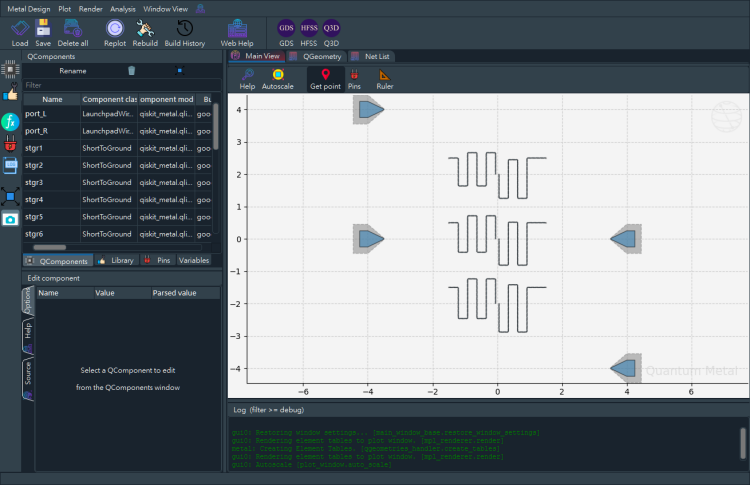

In [5]:
# setting resonator pattern
design.delete_all_components()
resonator_pattern(design=design)
gui.rebuild()
gui.autoscale()
gui.screenshot()

02:03AM 51s WARNING [make]: [TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:03AM 52s WARNING [make]: [TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:03AM 52s WARNING [make]: [TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL]         🎉 Destination Reached! Reconstructing Path...
[TL] ✂️ Smoothing diagonal path...
[TL] ✂️ Cleaning and smoothing trace...
[TL] 🏗️ Generating final Qiskit Metal geometry...
[TL] ✅ ROUTING COMPLETE!


[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Statefu

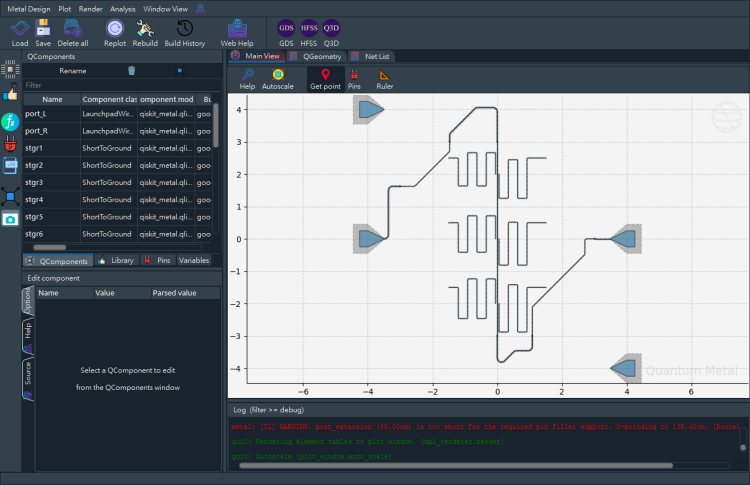

In [6]:

anchors = OrderedDict()
anchors[0] = np.array([0, 4])
anchors[1] = np.array([0, 0])
anchors[2] = np.array([0, -4])
chip_boundary = '200um'


T = RouteFlipChip(design, name="TL", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L", pin='tie'),
        end_pin=Dict(component="port_R", pin='tie')
    ),
    # --- Algorithm & Navigation Settings ---
        step_size='10um',                   # Grid size for the A* search pathfinder
        orthogonal_only='False',             # If True, forces strict 90-degree turns
        anchors=anchors,                          # User-defined waypoints: {0: [x1, y1], 1: [x2, y2]}
        ignore_escape_comps=['Resonator1','Resonator2','Resonator3','Resonator4','Resonator5','Resonator6'],              # List of components the router is allowed to route directly through
        
        # --- Trace Geometry (Exposed Planar Chip) ---
        bottom_layer='2',                    # Qiskit Metal layer for the exposed planar chip
        planar_trace_width='20um',           # CPW trace width when exposed to vacuum
        planar_trace_gap='12um',             # CPW gap width when exposed to vacuum
        planar_fillet='50um',                # Corner rounding radius for the exposed trace
        
        # --- Trace Geometry (Covered by Flip-Chip) ---
        top_layer='1',                       # Qiskit Metal layer for the covered flip-chip region
        flipchip_trace_width='10um',         # CPW trace width under the flip-chip (usually narrower)
        flipchip_trace_gap='6um',            # CPW gap width under the flip-chip
        flipchip_fillet='50um',              # Corner rounding radius for the covered trace
        
        # --- Connections & Transitions ---
        port_extension='50um',               # How far to route straight out of the start/end pins before turning
        transition_length='50um',            # Length of the smooth taper when changing width/gap at chip boundaries
        
        # --- Physical Chip Boundaries ---
        planar_size=['10mm', '10mm'],        # [width, height] of the base planar chip
        planar_center=['0mm', '0mm'],        # [x, y] coordinates of the planar chip's center
        flipchip_size=['6mm','6mm'],         # [width, height] of the top flip-chip
        flipchip_center=['0mm', '0mm'],      # [x, y] coordinates of the flip-chip's center
        
        # --- Clearances & Keep-Out Zones ---
        obstacle_buffer='20um',              # Invisible safety buffer around other components (prevents shorts)
        flipchip_boundary_buffer='200um',    # Keep-out margin to avoid routing too close to the flip-chip edge
        forbidden_corner_size=['200um','200um'], # Extra keep-out zones specifically at the chip corners
        port_keepout='1000um',
))

gui.rebuild()
gui.autoscale()
gui.screenshot()

02:03AM 56s WARNING [make]: [TL2] ⚠️ WARNING: 'planar_fillet' (5.0um) is too small. Overriding to safe minimum (132.0um).
02:03AM 56s WARNING [make]: [TL2] ⚠️ WARNING: 'flipchip_fillet' (5.0um) is too small. Overriding to safe minimum (66.0um).
02:03AM 56s WARNING [make]: [TL2] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL2] ⚠️ WARNING: 'planar_fillet' (5.0um) is too small. Overriding to safe minimum (132.0um).
[TL2] ⚠️ WARNING: 'flipchip_fillet' (5.0um) is too small. Overriding to safe minimum (66.0um).
[TL2] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL2] 🚀 STARTING ROUTER...
[TL2] 📍 Found 1 total segments to route.
[TL2]   ▶ Phase 1: Building collision tables...
[TL2]   ▶ Phase 2: Running Stateful Continuous A* Search...


02:03AM 59s WARNING [_draw_cpw_chunk]: [TL2] WARNING: A Planar internal trace segment is only 270.6um long. Forced to shrink the corner fillet to 132.0um, which is below the safe minimum of 132.0um.


[TL2]         🎉 Destination Reached! Reconstructing Path...
[TL2] ✂️ Cleaning and smoothing trace...
[TL2] 🏗️ Generating final Qiskit Metal geometry...
[TL2] WARNING: A Planar internal trace segment is only 270.6um long. Forced to shrink the corner fillet to 132.0um, which is below the safe minimum of 132.0um.
[TL2] ✅ ROUTING COMPLETE!


[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL]         🎉 Destination Reached! Reconstructing Path...
[TL] ✂️ Smoothing diagonal path...
[TL] ✂️ Cleaning and smoothing trace...
[TL] 🏗️ Generating final Qiskit Metal geometry...
[TL] ✅ ROUTING COMPLETE!


[TL2] 🚀 STARTING ROUTER...
[TL2] 📍 Found 1 total segments to route.
[TL2]   ▶ Phase 1: Building collision tab

02:04AM 03s WARNING [_draw_cpw_chunk]: [TL2] WARNING: A Planar internal trace segment is only 270.6um long. Forced to shrink the corner fillet to 132.0um, which is below the safe minimum of 132.0um.


[TL2]         🎉 Destination Reached! Reconstructing Path...
[TL2] ✂️ Cleaning and smoothing trace...
[TL2] 🏗️ Generating final Qiskit Metal geometry...
[TL2] WARNING: A Planar internal trace segment is only 270.6um long. Forced to shrink the corner fillet to 132.0um, which is below the safe minimum of 132.0um.
[TL2] ✅ ROUTING COMPLETE!



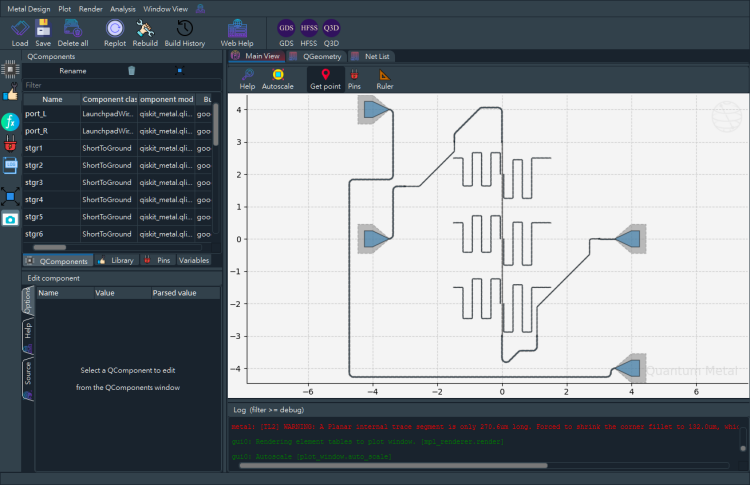

In [7]:

anchors2 = OrderedDict()
anchors2[0] = np.array([5, -4])
anchors2[1] = np.array([-4, 3])
T2 = RouteFlipChip(design, name="TL2", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L2", pin='tie'),
        end_pin=Dict(component="port_R2", pin='tie')
    ),
    # --- Algorithm & Navigation Settings ---
        step_size='10um',                   # Grid size for the A* search pathfinder
        orthogonal_only='True',             # If True, forces strict 90-degree turns
        #anchors=anchors2,                          # User-defined waypoints: {0: [x1, y1], 1: [x2, y2]}
        ignore_escape_comps=[],              # List of components the router is allowed to route directly through
        
        # --- Trace Geometry (Exposed Planar Chip) ---
        bottom_layer='2',                    # Qiskit Metal layer for the exposed planar chip
        planar_trace_width='20um',           # CPW trace width when exposed to vacuum
        planar_trace_gap='12um',             # CPW gap width when exposed to vacuum
        planar_fillet='5um',                # Corner rounding radius for the exposed trace
        
        # --- Trace Geometry (Covered by Flip-Chip) ---
        top_layer='1',                       # Qiskit Metal layer for the covered flip-chip region
        flipchip_trace_width='10um',         # CPW trace width under the flip-chip (usually narrower)
        flipchip_trace_gap='6um',            # CPW gap width under the flip-chip
        flipchip_fillet='5um',              # Corner rounding radius for the covered trace
        
        # --- Connections & Transitions ---
        port_extension='50um',               # How far to route straight out of the start/end pins before turning
        transition_length='50um',            # Length of the smooth taper when changing width/gap at chip boundaries
        
        # --- Physical Chip Boundaries ---
        planar_size=['10mm', '10mm'],        # [width, height] of the base planar chip
        planar_center=['0mm', '0mm'],        # [x, y] coordinates of the planar chip's center
        flipchip_size=['6mm','6mm'],         # [width, height] of the top flip-chip
        flipchip_center=['0mm', '0mm'],      # [x, y] coordinates of the flip-chip's center
        
        # --- Clearances & Keep-Out Zones ---
        obstacle_buffer='20um',              # Invisible safety buffer around other components (prevents shorts)
        flipchip_boundary_buffer='200um',    # Keep-out margin to avoid routing too close to the flip-chip edge
        forbidden_corner_size=['200um','200um'], # Extra keep-out zones specifically at the chip corners
        port_keepout='1mm',
))

gui.rebuild()
gui.autoscale()
gui.screenshot()

# Buffer test
In this case obstacle buffer = 30um feeed line will fail

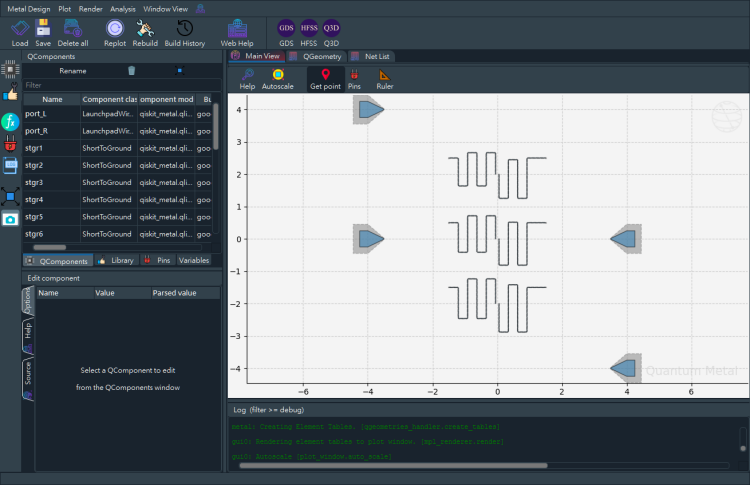

In [8]:
# setting resonator pattern
design.delete_all_components()
resonator_pattern(design=design)
gui.rebuild()
gui.autoscale()
gui.screenshot()

02:04AM 04s WARNING [make]: [TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 04s WARNING [make]: [TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 04s WARNING [make]: [TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.
02:04AM 04s ERROR [make]: [TL] A* failed to find a valid path.


[TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL] ❌ CRITICAL ERROR: Anchor (0, 0) is TRAPPED inside obstacle 'Resonator3_path_4'!
[TL] ❌ ROUTING FAILED.


02:04AM 04s ERROR [make]: [TL] A* failed to find a valid path.



[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL] ❌ CRITICAL ERROR: Anchor (0, 0) is TRAPPED inside obstacle 'Resonator3_path_4'!
[TL] ❌ ROUTING FAILED.


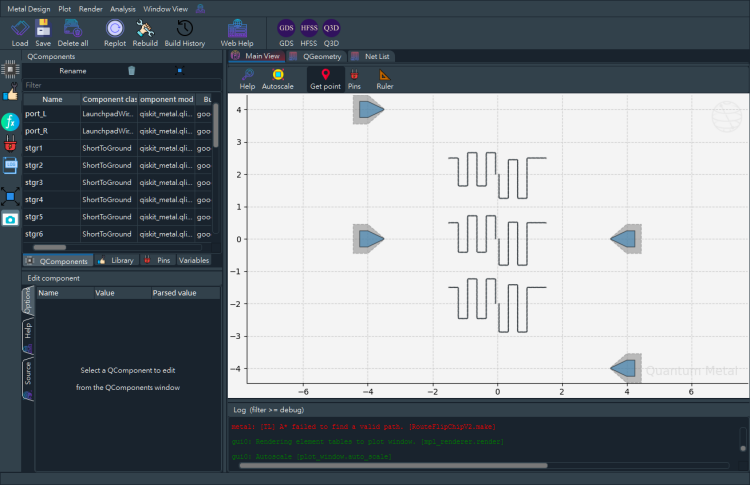

In [9]:

anchors = OrderedDict()
anchors[0] = np.array([0, 4])
anchors[1] = np.array([0, 0])
anchors[2] = np.array([0, -4])
chip_boundary = '200um'


T = RouteFlipChip(design, name="TL", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L", pin='tie'),
        end_pin=Dict(component="port_R", pin='tie')
    ),
    # --- Algorithm & Navigation Settings ---
        step_size='10um',                   # Grid size for the A* search pathfinder
        orthogonal_only='False',             # If True, forces strict 90-degree turns
        anchors=anchors,                          # User-defined waypoints: {0: [x1, y1], 1: [x2, y2]}
        ignore_escape_comps=['Resonator1','Resonator2','Resonator3','Resonator4','Resonator5','Resonator6'],              # List of components the router is allowed to route directly through
        
        # --- Trace Geometry (Exposed Planar Chip) ---
        bottom_layer='2',                    # Qiskit Metal layer for the exposed planar chip
        planar_trace_width='20um',           # CPW trace width when exposed to vacuum
        planar_trace_gap='12um',             # CPW gap width when exposed to vacuum
        planar_fillet='50um',                # Corner rounding radius for the exposed trace
        
        # --- Trace Geometry (Covered by Flip-Chip) ---
        top_layer='1',                       # Qiskit Metal layer for the covered flip-chip region
        flipchip_trace_width='10um',         # CPW trace width under the flip-chip (usually narrower)
        flipchip_trace_gap='6um',            # CPW gap width under the flip-chip
        flipchip_fillet='50um',              # Corner rounding radius for the covered trace
        
        # --- Connections & Transitions ---
        port_extension='50um',               # How far to route straight out of the start/end pins before turning
        transition_length='50um',            # Length of the smooth taper when changing width/gap at chip boundaries
        
        # --- Physical Chip Boundaries ---
        planar_size=['10mm', '10mm'],        # [width, height] of the base planar chip
        planar_center=['0mm', '0mm'],        # [x, y] coordinates of the planar chip's center
        flipchip_size=['6mm','6mm'],         # [width, height] of the top flip-chip
        flipchip_center=['0mm', '0mm'],      # [x, y] coordinates of the flip-chip's center
        
        # --- Clearances & Keep-Out Zones ---
        obstacle_buffer='30um',              # Invisible safety buffer around other components (prevents shorts)
        flipchip_boundary_buffer='200um',    # Keep-out margin to avoid routing too close to the flip-chip edge
        forbidden_corner_size=['200um','200um'], # Extra keep-out zones specifically at the chip corners
        port_keepout='1000um',
))

gui.rebuild()
gui.autoscale()
gui.screenshot()

# ignore_escape_comps test
If resonator didn't set as ignore_escape_comps, the feedline would fail due to port_extension

02:04AM 05s WARNING [make]: [TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 05s WARNING [make]: [TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 05s WARNING [make]: [TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.
02:04AM 05s ERROR [make]: [TL] A* failed to find a valid path.


[TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL] ❌ CRITICAL ERROR: Anchor (0, 0) is TRAPPED inside obstacle 'virtual_escape_zone_stgr3_short'!
[TL] ❌ ROUTING FAILED.


02:04AM 05s ERROR [make]: [TL] A* failed to find a valid path.



[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL] ❌ CRITICAL ERROR: Anchor (0, 0) is TRAPPED inside obstacle 'virtual_escape_zone_stgr3_short'!
[TL] ❌ ROUTING FAILED.


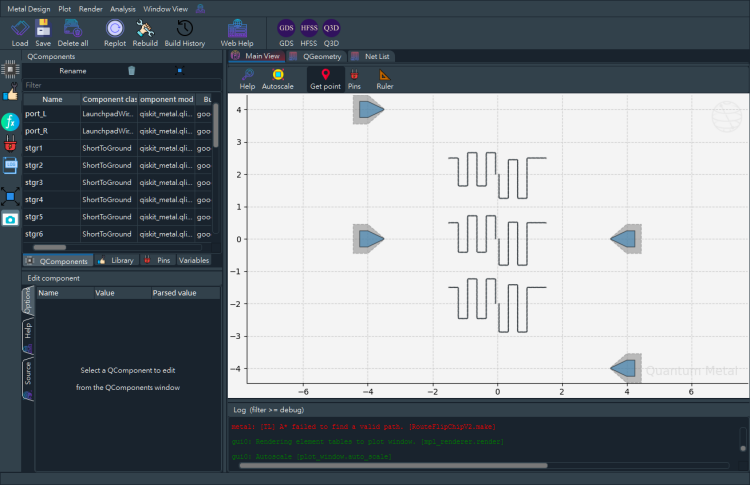

In [10]:

anchors = OrderedDict()
anchors[0] = np.array([0, 4])
anchors[1] = np.array([0, 0])
anchors[2] = np.array([0, -4])
chip_boundary = '200um'


T = RouteFlipChip(design, name="TL", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L", pin='tie'),
        end_pin=Dict(component="port_R", pin='tie')
    ),
    # --- Algorithm & Navigation Settings ---
        step_size='10um',                   # Grid size for the A* search pathfinder
        orthogonal_only='False',             # If True, forces strict 90-degree turns
        anchors=anchors,                          # User-defined waypoints: {0: [x1, y1], 1: [x2, y2]}
        ignore_escape_comps=[],              # List of components the router is allowed to route directly through
        
        # --- Trace Geometry (Exposed Planar Chip) ---
        bottom_layer='2',                    # Qiskit Metal layer for the exposed planar chip
        planar_trace_width='20um',           # CPW trace width when exposed to vacuum
        planar_trace_gap='12um',             # CPW gap width when exposed to vacuum
        planar_fillet='50um',                # Corner rounding radius for the exposed trace
        
        # --- Trace Geometry (Covered by Flip-Chip) ---
        top_layer='1',                       # Qiskit Metal layer for the covered flip-chip region
        flipchip_trace_width='10um',         # CPW trace width under the flip-chip (usually narrower)
        flipchip_trace_gap='6um',            # CPW gap width under the flip-chip
        flipchip_fillet='50um',              # Corner rounding radius for the covered trace
        
        # --- Connections & Transitions ---
        port_extension='50um',               # How far to route straight out of the start/end pins before turning
        transition_length='50um',            # Length of the smooth taper when changing width/gap at chip boundaries
        
        # --- Physical Chip Boundaries ---
        planar_size=['10mm', '10mm'],        # [width, height] of the base planar chip
        planar_center=['0mm', '0mm'],        # [x, y] coordinates of the planar chip's center
        flipchip_size=['6mm','6mm'],         # [width, height] of the top flip-chip
        flipchip_center=['0mm', '0mm'],      # [x, y] coordinates of the flip-chip's center
        
        # --- Clearances & Keep-Out Zones ---
        obstacle_buffer='20um',              # Invisible safety buffer around other components (prevents shorts)
        flipchip_boundary_buffer='200um',    # Keep-out margin to avoid routing too close to the flip-chip edge
        forbidden_corner_size=['200um','200um'], # Extra keep-out zones specifically at the chip corners
        port_keepout='1000um',
))

gui.rebuild()
gui.autoscale()
gui.screenshot()

# Anchor test


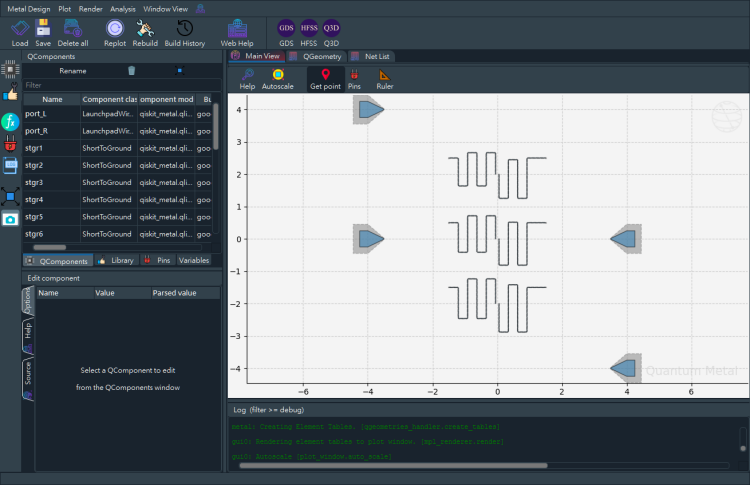

In [11]:
# setting resonator pattern
design.delete_all_components()
resonator_pattern(design=design)
gui.rebuild()
gui.autoscale()
gui.screenshot()

02:04AM 06s WARNING [make]: [TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 06s WARNING [make]: [TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 06s WARNING [make]: [TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL] ⚠️ ALERT: Anchor Modification Detected!
[TL]    The router detected an anchor exactly on the chip boundary.
[TL]    It has automatically split it to create a safe chip-to-chip transition.
[TL]    Original Anchors: [[0, 3], [0, 0], [0, -3]]
[TL]    Modified Anchors: [[0.0, 3.247], [0.0, 2.753], [0, 0], [0.0, -2.753], [0.0, -3.247]]

[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 6 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL]         ✅ Rea

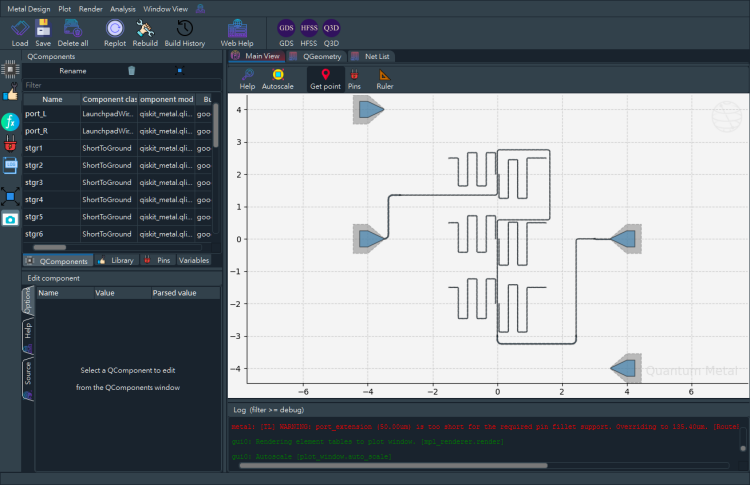

In [12]:
anchors = OrderedDict()
anchors[0] = np.array([0, 3])
anchors[1] = np.array([0, 0])
anchors[2] = np.array([0, -3])
chip_boundary = '200um'


T = RouteFlipChip(design, name="TL", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L", pin='tie'),
        end_pin=Dict(component="port_R", pin='tie')
    ),
    # --- Algorithm & Navigation Settings ---
        step_size='10um',                   # Grid size for the A* search pathfinder
        orthogonal_only='True',             # If True, forces strict 90-degree turns
        anchors=anchors,                          # User-defined waypoints: {0: [x1, y1], 1: [x2, y2]}
        ignore_escape_comps=[
    'Resonator1','Resonator2','Resonator3','Resonator4','Resonator5','Resonator6',
    
],
        # --- Trace Geometry (Exposed Planar Chip) ---
        bottom_layer='2',                    # Qiskit Metal layer for the exposed planar chip
        planar_trace_width='20um',           # CPW trace width when exposed to vacuum
        planar_trace_gap='12um',             # CPW gap width when exposed to vacuum
        planar_fillet='50um',                # Corner rounding radius for the exposed trace
        
        # --- Trace Geometry (Covered by Flip-Chip) ---
        top_layer='1',                       # Qiskit Metal layer for the covered flip-chip region
        flipchip_trace_width='10um',         # CPW trace width under the flip-chip (usually narrower)
        flipchip_trace_gap='6um',            # CPW gap width under the flip-chip
        flipchip_fillet='50um',              # Corner rounding radius for the covered trace
        
        # --- Connections & Transitions ---
        port_extension='50um',               # How far to route straight out of the start/end pins before turning
        transition_length='50um',            # Length of the smooth taper when changing width/gap at chip boundaries
        
        # --- Physical Chip Boundaries ---
        planar_size=['10mm', '10mm'],        # [width, height] of the base planar chip
        planar_center=['0mm', '0mm'],        # [x, y] coordinates of the planar chip's center
        flipchip_size=['6mm','6mm'],         # [width, height] of the top flip-chip
        flipchip_center=['0mm', '0mm'],      # [x, y] coordinates of the flip-chip's center
        
        # --- Clearances & Keep-Out Zones ---
        obstacle_buffer='20um',              # Invisible safety buffer around other components (prevents shorts)
        flipchip_boundary_buffer='200um',    # Keep-out margin to avoid routing too close to the flip-chip edge
        forbidden_corner_size=['200um','200um'], # Extra keep-out zones specifically at the chip corners
        port_keepout='1000um',
    
))

gui.rebuild()
gui.autoscale()
gui.screenshot()

In [13]:
anchors = OrderedDict()
anchors[0] = np.array([0, 3.5])
anchors[1] = np.array([0, 0])
anchors[2] = np.array([0, -3.5])
chip_boundary = '200um'
T = RouteFlipChip(design, name="TL", options=Dict(
    pin_inputs=Dict(
        start_pin=Dict(component="port_L", pin='tie'),
        end_pin=Dict(component="port_R", pin='tie')
    ),
        step_size='10um',               
        orthogonal_only='True',            
        anchors=anchors,                
        ignore_escape_comps=['Resonator1','Resonator2','Resonator3','Resonator4','Resonator5','Resonator6'],
        bottom_layer='2',                  
        planar_trace_width='20um',           
        planar_trace_gap='12um',             
        planar_fillet='50um',               
        top_layer='1',                     
        flipchip_trace_width='10um',        
        flipchip_trace_gap='6um',            
        flipchip_fillet='50um',             
        port_extension='50um',         
        transition_length='50um',           
        planar_size=['10mm', '10mm'],  
        planar_center=['0mm', '0mm'], 
        flipchip_size=['6mm','6mm'],        
        flipchip_center=['0mm', '0mm'],      
        obstacle_buffer='20um',   
        flipchip_boundary_buffer='200um',   
        forbidden_corner_size=['200um','200um'], 
        port_keepout='1000um',
))

02:04AM 15s WARNING [make]: [TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 15s WARNING [make]: [TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 15s WARNING [make]: [TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL]         🎉 Destination Reached! Reconstructing Path...
[TL] ✂️ Cleaning and smoothing trace...
[TL] 🏗️ Generating final Qiskit Metal geometry...
[TL] ✅ ROUTING COMPLETE!



# Qiskit metal example test


## Automated validation suite (workspace version)

The cells below reload `RouteFlipChipV2.py` from the same folder as this notebook and run requirement-focused checks.

They cover:
- dual-plane routing with transition polygons on both layers
- hard-anchor compliance away from the flip-chip boundary
- orthogonal mode staying Manhattan
- safety overrides for too-small fillets and short port extensions
- benchmark regressions for `ignore_escape_comps` and `obstacle_buffer`
- exact flip-chip-boundary anchors being auto-split into safe inner/outer waypoints


In [14]:
# AUTO-VALIDATION HELPERS
from collections import OrderedDict
from shapely.geometry import Point, LineString
from shapely.ops import unary_union
from qiskit_metal import designs, Dict
import numpy as np

VALIDATION_IGNORE = [
    'Resonator1', 'Resonator2', 'Resonator3',
    'Resonator4', 'Resonator5', 'Resonator6'
]


def ordered_anchors(*points):
    anchors = OrderedDict()
    for idx, point in enumerate(points):
        anchors[idx] = np.array(point, dtype=float)
    return anchors



def make_validation_design():
    design = designs.DesignPlanar()
    design.overwrite_enabled = True
    design.chips.main.size.size_x = '10 mm'
    design.chips.main.size.size_y = '10 mm'
    design.chips.main.size.size_z = '-530 um'
    design.chips.main.material = 'silicon'
    resonator_pattern(design=design)
    return design



def make_route_options(start_component='port_L', end_component='port_R', anchors=None, **overrides):
    if anchors is None:
        anchors = OrderedDict()

    options = Dict(
        pin_inputs=Dict(
            start_pin=Dict(component=start_component, pin='tie'),
            end_pin=Dict(component=end_component, pin='tie')
        ),
        step_size='10um',
        orthogonal_only='False',
        anchors=anchors,
        ignore_escape_comps=list(VALIDATION_IGNORE),
        bottom_layer='2',
        planar_trace_width='20um',
        planar_trace_gap='12um',
        planar_fillet='50um',
        top_layer='1',
        flipchip_trace_width='10um',
        flipchip_trace_gap='6um',
        flipchip_fillet='50um',
        port_extension='50um',
        transition_length='50um',
        planar_size=['10mm', '10mm'],
        planar_center=['0mm', '0mm'],
        flipchip_size=['6mm', '6mm'],
        flipchip_center=['0mm', '0mm'],
        obstacle_buffer='20um',
        flipchip_boundary_buffer='200um',
        forbidden_corner_size=['200um', '200um'],
        port_keepout='1000um'
    )

    for key, value in overrides.items():
        options[key] = value
    return options



def build_route_case(case_name, start_component='port_L', end_component='port_R', anchors=None, **overrides):
    design = make_validation_design()
    options = make_route_options(
        start_component=start_component,
        end_component=end_component,
        anchors=anchors,
        **overrides,
    )
    route = RouteFlipChip(design, name=case_name, options=options)
    return design, route



def component_table(design, component, table_name):
    table = design.qgeometry.tables[table_name]
    subset = table[table['component'] == component.id].copy()
    return subset



def trace_rows(design, component):
    rows = component_table(design, component, 'path')
    if rows.empty:
        return rows
    if 'subtract' in rows.columns:
        rows = rows[rows['subtract'] == False]
    return rows



def taper_rows(design, component):
    rows = component_table(design, component, 'poly')
    if rows.empty:
        return rows
    if 'name' in rows.columns:
        mask = rows['name'].astype(str).str.contains('taper_trace_')
    else:
        mask = rows.index.astype(str).str.contains('taper_trace_')
    return rows[mask]



def route_union(design, component):
    rows = trace_rows(design, component)
    geometries = [geom for geom in rows.get('geometry', []).tolist() if geom is not None and not geom.is_empty]
    return unary_union(geometries) if geometries else LineString()



def assert_true(condition, message):
    if not condition:
        raise AssertionError(message)



def assert_route_has_geometry(design, component):
    rows = trace_rows(design, component)
    assert_true(not rows.empty, f"{component.name} did not produce any trace geometry.")
    return rows



def assert_path_hits_points(design, component, points, tol=5e-4):
    routed = route_union(design, component)
    for point in points:
        dist = routed.distance(Point(point))
        assert_true(dist <= tol, f"{component.name} missed required point {tuple(point)} by {dist:.6g} mm.")



def assert_orthogonal_paths(design, component, tol=1e-9):
    rows = assert_route_has_geometry(design, component)
    for geom in rows['geometry']:
        coords = list(geom.coords)
        for a, b in zip(coords, coords[1:]):
            dx = abs(b[0] - a[0])
            dy = abs(b[1] - a[1])
            assert_true(dx <= tol or dy <= tol, f"{component.name} produced a diagonal segment from {a} to {b}.")



def assert_transition_layers(design, component, expected_layers=(1, 2)):
    rows = taper_rows(design, component)
    if rows.empty:
        all_poly = component_table(design, component, 'poly')
        available_names = all_poly['name'].astype(str).tolist() if 'name' in all_poly.columns else []
        raise AssertionError(f"{component.name} did not create any taper polygons. Available poly names: {available_names}")
    actual_layers = set(int(layer) for layer in rows['layer'].tolist())
    assert_true(actual_layers == set(expected_layers), f"Expected taper layers {set(expected_layers)}, got {actual_layers}.")



def assert_trace_layers(design, component, expected_layers=(1, 2)):
    rows = assert_route_has_geometry(design, component)
    actual_layers = set(int(layer) for layer in rows['layer'].tolist())
    assert_true(actual_layers == set(expected_layers), f"Expected trace layers {set(expected_layers)}, got {actual_layers}.")



def endpoint_segment_length(design, component, pin_name, tol=1e-6):
    rows = assert_route_has_geometry(design, component)
    pin_pt = Point(component.pins[pin_name]['middle'])
    for geom in rows['geometry']:
        coords = list(geom.coords)
        if len(coords) < 2:
            continue
        if pin_pt.distance(Point(coords[0])) <= tol:
            return float(np.linalg.norm(np.array(coords[1]) - np.array(coords[0])))
        if pin_pt.distance(Point(coords[-1])) <= tol:
            return float(np.linalg.norm(np.array(coords[-1]) - np.array(coords[-2])))
    raise AssertionError(f"Could not find a trace segment attached to pin '{pin_name}' on {component.name}.")


In [15]:
# AUTO-VALIDATION RUNNER
validation_results = []


def record(case_name, detail=''):
    validation_results.append((case_name, 'PASS', detail))


# 1. Dual-plane routing, transitions, and hard anchors away from the boundary.
diag_anchors = ordered_anchors((0.0, 4.0), (0.0, 0.0), (0.0, -4.0))
design_diag, route_diag = build_route_case(
    'TL_validate_dual_plane',
    anchors=diag_anchors,
    orthogonal_only='False',
)
assert_trace_layers(design_diag, route_diag, expected_layers=(1, 2))
assert_transition_layers(design_diag, route_diag, expected_layers=(1, 2))
assert_path_hits_points(design_diag, route_diag, list(diag_anchors.values()))
record('dual_plane_transition', 'Both routing layers and taper polygons were generated, and all anchors were hit.')


# 2. Orthogonal mode must remain Manhattan while still honoring anchors.
ortho_anchors = ordered_anchors((0.0, 2.5), (0.0, 0.0), (0.0, -2.5))
design_ortho, route_ortho = build_route_case(
    'TL_validate_orthogonal',
    anchors=ortho_anchors,
    orthogonal_only='True',
)
assert_orthogonal_paths(design_ortho, route_ortho)
assert_path_hits_points(design_ortho, route_ortho, list(ortho_anchors.values()))
record('orthogonal_mode', 'All routed segments stayed Manhattan and preserved the requested anchor chain.')


# 3. Safety overrides must rescue undersized fillets and short straight exits.
design_safe, route_safe = build_route_case(
    'TL_validate_safety',
    start_component='port_L2',
    end_component='port_R2',
    orthogonal_only='True',
    ignore_escape_comps=[],
    planar_fillet='5um',
    flipchip_fillet='5um',
    port_extension='10um',
    port_keepout='1mm',
)
assert_route_has_geometry(design_safe, route_safe)
planar_min = 3.0 * (route_safe.parse_value(route_safe.p.planar_trace_width) + 2 * route_safe.parse_value(route_safe.p.planar_trace_gap))
flipchip_min = 3.0 * (route_safe.parse_value(route_safe.p.flipchip_trace_width) + 2 * route_safe.parse_value(route_safe.p.flipchip_trace_gap))
planar_fillet = route_safe.parse_value(route_safe.p.planar_fillet)
flipchip_fillet = route_safe.parse_value(route_safe.p.flipchip_fillet)
assert_true(planar_fillet >= planar_min - 1e-9, f"Planar fillet override failed: {planar_fillet} < {planar_min}")
assert_true(flipchip_fillet >= flipchip_min - 1e-9, f"Flip-chip fillet override failed: {flipchip_fillet} < {flipchip_min}")
start_seg_len = endpoint_segment_length(design_safe, route_safe, 'start')
end_seg_len = endpoint_segment_length(design_safe, route_safe, 'end')
assert_true(start_seg_len + 1e-6 >= 1.025 * planar_fillet, f"Start straight is too short: {start_seg_len} mm")
assert_true(end_seg_len + 1e-6 >= 1.025 * planar_fillet, f"End straight is too short: {end_seg_len} mm")
record('safety_overrides', 'Tiny fillets were auto-raised and the entry/exit terminal straights remained long enough for a single endpoint fillet.')


# 4. In this resonator benchmark, ignore_escape_comps should decide feasibility.
design_allow, route_allow = build_route_case(
    'TL_validate_ignore_allow',
    anchors=diag_anchors,
    orthogonal_only='False',
    ignore_escape_comps=list(VALIDATION_IGNORE),
)
assert_route_has_geometry(design_allow, route_allow)

design_block, route_block = build_route_case(
    'TL_validate_ignore_block',
    anchors=diag_anchors,
    orthogonal_only='False',
    ignore_escape_comps=[],
)
blocked_rows = trace_rows(design_block, route_block)
assert_true(blocked_rows.empty, 'Expected no valid routed geometry when ignore_escape_comps is disabled in this benchmark.')
record('ignore_escape_comps_regression', 'The benchmark stays routable only when the resonator escape zones are whitelisted.')


# 5. In this benchmark, increasing obstacle_buffer to 30 um should close the corridor.
design_buf_ok, route_buf_ok = build_route_case(
    'TL_validate_buffer_ok',
    anchors=diag_anchors,
    orthogonal_only='False',
    obstacle_buffer='20um',
)
assert_route_has_geometry(design_buf_ok, route_buf_ok)

design_buf_fail, route_buf_fail = build_route_case(
    'TL_validate_buffer_fail',
    anchors=diag_anchors,
    orthogonal_only='False',
    obstacle_buffer='30um',
)
blocked_buffer_rows = trace_rows(design_buf_fail, route_buf_fail)
assert_true(blocked_buffer_rows.empty, 'Expected the 30 um obstacle buffer benchmark to become unroutable.')
record('obstacle_buffer_regression', 'The 20 um corridor routes, while the 30 um corridor closes as expected for this layout.')


# 6. Anchors exactly on the flip-chip boundary should be auto-split to safe inner/outer waypoints.
boundary_anchors = ordered_anchors((0.0, 3.0), (0.0, 0.0), (0.0, -3.0))
design_boundary, route_boundary = build_route_case(
    'TL_validate_boundary_split',
    anchors=boundary_anchors,
    orthogonal_only='True',
)
protected = getattr(route_boundary, '_protected_anchors', set())
assert_true(len(protected) > len(boundary_anchors), 'Boundary anchors were not expanded into additional protected waypoints.')
assert_true((0.0, 3.0) not in protected and (0.0, -3.0) not in protected, 'Exact boundary anchors should be replaced by safe split points.')
record('boundary_anchor_split', f'Protected anchor set expanded to {len(protected)} waypoints after boundary splitting.')


print('Validation summary:')
for case_name, status, detail in validation_results:
    print(f'- {case_name}: {status} | {detail}')


02:04AM 20s WARNING [make]: [TL_validate_dual_plane] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 20s WARNING [make]: [TL_validate_dual_plane] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 20s WARNING [make]: [TL_validate_dual_plane] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL_validate_dual_plane] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL_validate_dual_plane] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL_validate_dual_plane] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL_validate_dual_plane] 🚀 STARTING ROUTER...
[TL_validate_dual_plane] 📍 Found 4 total segments to route.
[TL_validate_dual_plane]   ▶ Phase 1: Building collision tables...
[TL_validate_dual_plane]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL_validate_dual_plane]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL_validate_dual_plane]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL_validate_dual_plane]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL_validate_dual_plane]         🎉 Destination Reached! Reconstructing Path...
[TL_validate_dual_plane] ✂️ Smoothing diagonal path...
[TL_validate_dual_plane

02:04AM 22s WARNING [make]: [TL_validate_orthogonal] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 22s WARNING [make]: [TL_validate_orthogonal] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 22s WARNING [make]: [TL_validate_orthogonal] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL_validate_orthogonal] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL_validate_orthogonal] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL_validate_orthogonal] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL_validate_orthogonal] 🚀 STARTING ROUTER...
[TL_validate_orthogonal] 📍 Found 4 total segments to route.
[TL_validate_orthogonal]   ▶ Phase 1: Building collision tables...
[TL_validate_orthogonal]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL_validate_orthogonal]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL_validate_orthogonal]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL_validate_orthogonal]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL_validate_orthogonal]         ... searching. Explored 5000 nodes. Target 3/4.
[TL_validate_orthogonal]         🎉 Destination Reached! Reconstructing Path.

02:04AM 27s WARNING [make]: [TL_validate_safety] ⚠️ WARNING: 'planar_fillet' (5.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 27s WARNING [make]: [TL_validate_safety] ⚠️ WARNING: 'flipchip_fillet' (5.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 27s WARNING [make]: [TL_validate_safety] WARNING: port_extension (10.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL_validate_safety] ⚠️ WARNING: 'planar_fillet' (5.0um) is too small. Overriding to safe minimum (132.0um).
[TL_validate_safety] ⚠️ WARNING: 'flipchip_fillet' (5.0um) is too small. Overriding to safe minimum (66.0um).
[TL_validate_safety] WARNING: port_extension (10.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL_validate_safety] 🚀 STARTING ROUTER...
[TL_validate_safety] 📍 Found 1 total segments to route.
[TL_validate_safety]   ▶ Phase 1: Building collision tables...
[TL_validate_safety]   ▶ Phase 2: Running Stateful Continuous A* Search...


... (8 outputs left out)

02:04AM 33s WARNING [make]: [TL_validate_buffer_fail] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 33s WARNING [make]: [TL_validate_buffer_fail] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 33s WARNING [make]: [TL_validate_buffer_fail] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.
02:04AM 33s ERROR [make]: [TL_validate_buffer_fail] A* failed to find a valid path.


[TL_validate_buffer_fail] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL_validate_buffer_fail] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL_validate_buffer_fail] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL_validate_buffer_fail] 🚀 STARTING ROUTER...
[TL_validate_buffer_fail] 📍 Found 4 total segments to route.
[TL_validate_buffer_fail]   ▶ Phase 1: Building collision tables...
[TL_validate_buffer_fail]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL_validate_buffer_fail] ❌ CRITICAL ERROR: Anchor (0.0, 0.0) is TRAPPED inside obstacle 'Resonator3_path_4'!
[TL_validate_buffer_fail] ❌ ROUTING FAILED.


02:04AM 33s WARNING [make]: [TL_validate_boundary_split] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
02:04AM 33s WARNING [make]: [TL_validate_boundary_split] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
02:04AM 33s WARNING [make]: [TL_validate_boundary_split] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.


[TL_validate_boundary_split] ⚠️ WARNING: 'planar_fillet' (50.0um) is too small. Overriding to safe minimum (132.0um).
[TL_validate_boundary_split] ⚠️ WARNING: 'flipchip_fillet' (50.0um) is too small. Overriding to safe minimum (66.0um).
[TL_validate_boundary_split] WARNING: port_extension (50.00um) is too short for the required pin fillet support. Overriding to 135.40um.

[TL_validate_boundary_split] ⚠️ ALERT: Anchor Modification Detected!
[TL_validate_boundary_split]    The router detected an anchor exactly on the chip boundary.
[TL_validate_boundary_split]    It has automatically split it to create a safe chip-to-chip transition.
[TL_validate_boundary_split]    Original Anchors: [[0.0, 3.0], [0.0, 0.0], [0.0, -3.0]]
[TL_validate_boundary_split]    Modified Anchors: [[0.0, 3.247], [0.0, 2.753], [0.0, 0.0], [0.0, -2.753], [0.0, -3.247]]

[TL_validate_boundary_split] 🚀 STARTING ROUTER...
[TL_validate_boundary_split] 📍 Found 6 total segments to route.
[TL_validate_boundary_split]   ▶ Pha

In [16]:
gui.rebuild()


[TL] 🚀 STARTING ROUTER...
[TL] 📍 Found 4 total segments to route.
[TL]   ▶ Phase 1: Building collision tables...
[TL]   ▶ Phase 2: Running Stateful Continuous A* Search...
[TL]         ✅ Reached Anchor 1! Routing to Anchor 2...
[TL]         ✅ Reached Anchor 2! Routing to Anchor 3...
[TL]         ✅ Reached Anchor 3! Routing to Anchor 4...
[TL]         🎉 Destination Reached! Reconstructing Path...
[TL] ✂️ Cleaning and smoothing trace...
[TL] 🏗️ Generating final Qiskit Metal geometry...
[TL] ✅ ROUTING COMPLETE!

